# TATA VISION — Universal "Draw Anything" Geometry Tutorial

**One notebook that analyses a photo first, then picks the right drawing method for every thing it finds.**

This merges your three notebooks (*Human Sketch V3 Landmarks*, *Object Structure Sketch*, *Step-by-Step Geometry*) into one pipeline and fixes the problems found in them.

```
                        ┌─────────────────────────────┐
  your photo ─────────► │  1. ANALYSE THE IMAGE       │  YOLO segmentation + YOLO pose + 68-pt face landmarks
                        └──────────────┬──────────────┘
         ┌───────────────┬─────────────┼───────────────┬──────────────────┐
         ▼               ▼             ▼               ▼                  ▼
    HUMAN BODY       HUMAN FACE     ANIMAL /         ANYTHING ELSE     WHOLE-PICTURE
    7 steps          9 steps        BIRD / PLANT     (cup, chair,      SHAPE MAP
    pose geometry    68 landmarks   7 steps          car, bottle…)     (always available)
    head→limbs       eyes→shading   ellipse+circles  SAM segments →    SAM segments →
                                    +spine+limbs     ≤5 basic shapes   ≤5 basic shapes
                                                     per part + lines  per part, big→small
```

**What a beginner gets for every subject:** numbered step images (new strokes **dark**, earlier steps **grey**), a contact-sheet board, an overlay on the original photo, and an editable **SVG** of every step.

### What was fixed compared with the three originals
| Original problem | Fix in this notebook |
|---|---|
| Three separate notebooks, `geometry_pipeline_v7.py`, `…_fusion_integrated.py` etc. missing on other machines | **One self-contained file** — no hidden `.py` modules |
| You had to choose the notebook (face / body / object) yourself | **Automatic routing** after analysing the image |
| Face: head oval off-centre from the jaw, ears floating outside the head, hair arc not joined to the jaw, harsh noisy shading | Head oval fitted to the **jaw extremes**, ears attached at the oval edge between brow line and nose base, closed head outline, smooth 4-tone value map |
| Body: head size taken from shoulder width (collapses in side view), mask width measured across the arms | Head sized from torso length (+ face landmarks when available), side-view depth measured **perpendicular to the spine** and clamped, far limbs drawn dashed |
| Objects: ellipse axes were 1.6σ instead of 2σ, results drawn tiny on a full-size canvas, `IMAGE_PATH` used before it was defined, 7 duplicate "sheep" for one chart | Correct PCA ellipse on the thick body core, **every subject cropped and enlarged**, class-agnostic NMS, clean variable flow |
| Skeleton SVG was thousands of 1-pixel row segments | Every step is exported as **real vector primitives** (lines, ellipses, circles, polygons) |
| Nothing for objects the detector does not know | **Geometric shape decomposition** (circle / ellipse / rectangle / triangle fit per part) + whole-picture shape map |

> **Honest limits:** these are *construction guides*, not anatomy. The skeleton of an animal is a 2-D silhouette skeleton, not real bones; COCO models can mislabel unusual animals (use `USE_OPEN_VOCAB=True` for lion, fox, tree, flower …). Always look at the "analysis" figure before trusting a result.

## 1. Install (run once)
Python 3.10 – 3.12 recommended. In Colab just run it. Model weights download automatically the first time they are used.

In [1]:
%pip install -q ultralytics opencv-python-headless numpy scipy scikit-image matplotlib pillow requests face-alignment segment-anything

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and your settings
**Only this cell needs editing.**

In [2]:
import math, io, os, shutil, time, warnings
from dataclasses import dataclass, field
from collections import deque
from pathlib import Path
from typing import Optional, List

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.morphology import skeletonize
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

warnings.filterwarnings("ignore")

# ───────────────────────── USER SETTINGS ─────────────────────────
IMAGE_SOURCE    = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS2LdJv4ntCGvMZnFl2_V8vgQRuaVU6D5s95mSZBIWnRrTwQ4QbhVDAhwE&s=10"          # "photo.jpg"  |  "https://…/image.jpg"  |  None → Colab upload, else built-in demo image
OUTPUT_DIR      = Path("tatavision_output")

MODEL_SIZE      = "n"           # YOLO size: 'n' fastest · 's' · 'm' more accurate (slower, bigger download)
CONF            = 0.25          # detection confidence
MAX_IMAGE_SIDE  = 1600          # larger photos are shrunk to this (pixels)
MAX_ITEMS       = 8             # at most this many subjects are drawn (largest first)
MIN_ITEM_FRAC   = 0.004         # ignore objects smaller than this fraction of the picture

DETECT_FACES    = True          # 68-point face landmarks (needs `face-alignment`)
USE_OPEN_VOCAB  = False         # True → also search OPEN_VOCAB words with YOLO-World + SAM (slower, bigger download)
OPEN_VOCAB      = ["lion", "tiger", "fox", "deer", "rabbit", "monkey", "parrot", "eagle", "owl", "butterfly",
                   "tree", "palm tree", "flower", "rose", "sunflower", "lotus", "cactus"]

SCENE_SHAPE_MAP = True          # also build a beginner "basic shapes" map of the WHOLE picture

# ── geometric branch: SAM "segment everything" + multi-primitive reconstruction ──
SEGMENT_ENGINE      = "auto"    # 'auto' → official SAM, else Ultralytics SAM, else colour k-means  |  or force one of:
                                #   'sam_official' | 'sam_ultralytics' | 'kmeans'
SAM_MODEL_TYPE      = "vit_h"   # vit_h (best, 2.5 GB) | vit_l | vit_b (fastest, 375 MB — use on CPU)
SAM_CHECKPOINT_DIR  = Path("sam_checkpoints")
TARGET_COVERAGE     = 0.80      # rebuild this much of every segment from basic shapes …
MAX_SHAPES_PER_PART = 5         # … using at most this many shapes per segment
MAX_OUTSIDE_RATIO   = 0.03      # a shape may leave its segment by at most 3 %
MIN_COMPONENT_AREA  = 60        # ignore segments smaller than this (pixels)
MAX_REGION_AREA_RATIO = 0.60    # ignore a segment bigger than this fraction of the picture (= background)
MAX_COMPONENTS      = 200       # safety cap on segments processed
SCENE_MAX_PARTS     = 60        # the whole-picture map draws at most this many (largest) parts — keeps it readable
HIGHLIGHT_NEW   = True          # newest strokes dark, earlier steps grey (set False for all-dark steps)
SAVE_SVG        = True          # editable vector file for every step
# ─────────────────────────────────────────────────────────────────

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"
print("Device:", DEVICE)

Device: cpu


## 3. Load the image
Works with a local path, a web URL, a Colab upload, or the built-in demo picture.

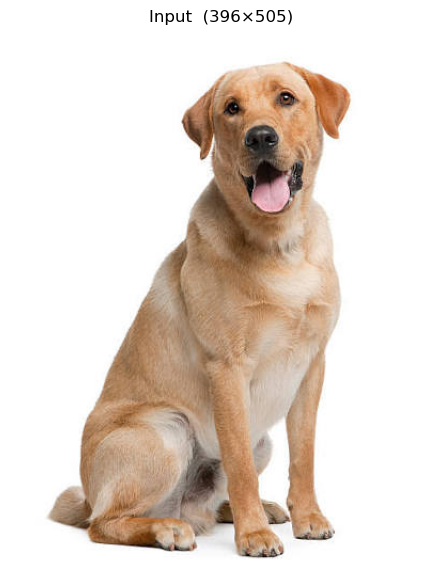

In [3]:
def load_image(source=None, max_side=MAX_IMAGE_SIDE):
    """Return an RGB uint8 image (H, W, 3)."""
    rgb = None
    if source is None:
        try:                                            # Google Colab upload
            from google.colab import files
            uploaded = files.upload()
            source = next(iter(uploaded))
        except Exception:
            source = None
    if source is None:
        from skimage import data
        print("IMAGE_SOURCE is None → using the built-in demo photo. Set IMAGE_SOURCE to your own picture.")
        rgb = data.astronaut()
    elif str(source).startswith(("http://", "https://")):
        import requests
        r = requests.get(source, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        bgr = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
        if bgr is None:
            raise ValueError("The URL did not return a readable image.")
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    else:
        bgr = cv2.imread(str(source), cv2.IMREAD_COLOR)
        if bgr is None:
            raise FileNotFoundError(f"Cannot read image: {source}")
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    h, w = rgb.shape[:2]
    s = min(1.0, max_side / max(h, w))
    if s < 1:
        rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return np.ascontiguousarray(rgb)


img = load_image(IMAGE_SOURCE)
H, W = img.shape[:2]
plt.figure(figsize=(7, 7)); plt.imshow(img); plt.axis("off"); plt.title(f"Input  ({W}×{H})"); plt.show()

## 4. Shared drawing engine
Every branch (body, face, animal, object, scene) draws **vector primitives** into a `Sketch`.
The same primitives are rendered to PNG (with "new stroke = dark, old = grey" highlighting), overlaid on the photo, or exported as SVG.
Each sketch is automatically cropped and enlarged to its subject, so tiny subjects in a big photo are still drawn large and crisp.

In [4]:
# style → (colour when NEW, colour when OLD, pen width in pixels on a ~900 px canvas)
STYLE = {
    "main":  ((25, 25, 25),   (140, 140, 140), 4),   # the shapes you actually draw
    "thin":  ((60, 60, 60),   (165, 165, 165), 3),   # secondary / far-side forms
    "guide": ((70, 130, 230), (190, 208, 238), 2),   # construction guides (light blue pencil)
    "soft":  ((110, 110, 110), (200, 200, 200), 2),  # numbers, notes
}
# colour-coded shape types (same idea as your "typed" view)
TYPED_COL = {"circle": (230, 40, 40), "ellipse": (30, 160, 60), "rectangle": (40, 80, 230), "square": (255, 140, 0),
             "triangle": (170, 40, 190), "line": (130, 80, 30), "curve": (0, 160, 190)}
STYLE["t_line"] = (TYPED_COL["line"], (205, 190, 170), 4)          # straight edges
STYLE["t_curve"] = (TYPED_COL["curve"], (170, 215, 225), 4)        # curved edges
OVERLAY_COL = {"main": (255, 210, 0), "thin": (255, 210, 0), "guide": (0, 220, 255), "soft": (255, 255, 255),
               "t_line": TYPED_COL["line"], "t_curve": TYPED_COL["curve"]}


def ascii_clean(s):
    """OpenCV fonts are ASCII-only: swap typographic symbols for plain ones."""
    for a, b in (("·", "/"), ("—", "-"), ("–", "-"), ("×", "x"), ("°", " deg"), ("→", "->"), ("…", "..."), ("÷", "/")):
        s = s.replace(a, b)
    return s.encode("ascii", "replace").decode()


def unit(v, eps=1e-9):
    v = np.asarray(v, float)
    n = np.linalg.norm(v)
    return v / n if n > eps else np.zeros_like(v)


def lerp(a, b, t):
    return a + (b - a) * t


def ang_deg(v):
    return math.degrees(math.atan2(v[1], v[0]))


def capsule_outline(a, r1, b, r2, n=10):
    """Closed outline of a tapered capsule (round end of radius r1 at a, r2 at b)."""
    a = np.asarray(a, float); b = np.asarray(b, float)
    d = b - a
    L = np.linalg.norm(d)
    if L < 1e-6:
        return None
    th = math.atan2(d[1], d[0])
    phi = math.acos(float(np.clip((r1 - r2) / L, -1, 1)))
    pts = []
    for t in np.linspace(th + phi, th + 2 * math.pi - phi, n):   # round back of circle 1
        pts.append(a + r1 * np.array([math.cos(t), math.sin(t)]))
    for t in np.linspace(th - phi, th + phi, n):                  # round front of circle 2
        pts.append(b + r2 * np.array([math.cos(t), math.sin(t)]))
    return pts


class Sketch:
    """A step-by-step vector drawing. Points are always stored in ORIGINAL-IMAGE coordinates."""

    def __init__(self, name=""):
        self.name = name
        self.prims = []
        self.step = 0
        self.titles = {}
        self.solo = set()          # steps that are drawn ALONE (clean final versions)
        self.target = 900
        self.margin = 0.08
        self._tf = None

    # ---- building ----
    def next_step(self, title):
        self.step += 1
        self.titles[self.step] = title
        return self.step

    def _add(self, kind, style, **kw):
        self.prims.append(dict(kind=kind, style=style, step=self.step, **kw))
        self._tf = None

    def poly(self, pts, style="main", closed=False, dash=False, tag=None):
        pts = [tuple(map(float, p)) for p in pts if p is not None]
        if len(pts) >= 2:
            self._add("poly", style, pts=pts, closed=closed, dash=dash, tag=tag)

    def line(self, a, b, style="main", dash=False):
        if a is not None and b is not None:
            self.poly([a, b], style, False, dash)

    def circle(self, c, r, style="main", tag=None):
        if c is not None and r > 0:
            self._add("circle", style, c=tuple(map(float, c)), r=float(r), tag=tag)

    def ellipse(self, c, a, b, angle_deg, style="main", tag=None):
        """Semi-axis `a` lies along `angle_deg`; semi-axis `b` is perpendicular to it."""
        if c is not None and a > 0 and b > 0:
            self._add("ellipse", style, c=tuple(map(float, c)), a=float(a), b=float(b), ang=float(angle_deg), tag=tag)

    def dot(self, p, style="main", r=None):
        if p is not None:
            self._add("dot", style, c=tuple(map(float, p)), r=r)

    def text(self, p, s, style="soft"):
        if p is not None:
            self._add("text", style, c=tuple(map(float, p)), s=str(s))

    def capsule(self, p1, r1, p2, r2, style="main", tag=None):
        out = capsule_outline(p1, r1, p2, r2)
        if out is not None:
            self.poly(out, style, closed=True, tag=tag)

    # ---- geometry of the output frame ----
    def _bounds(self):
        xs, ys = [], []
        for p in self.prims:
            if p["kind"] == "poly":
                for x, y in p["pts"]:
                    xs.append(x); ys.append(y)
            elif p["kind"] in ("circle",):
                xs += [p["c"][0] - p["r"], p["c"][0] + p["r"]]; ys += [p["c"][1] - p["r"], p["c"][1] + p["r"]]
            elif p["kind"] == "ellipse":
                m = max(p["a"], p["b"])
                xs += [p["c"][0] - m, p["c"][0] + m]; ys += [p["c"][1] - m, p["c"][1] + m]
            else:
                xs.append(p["c"][0]); ys.append(p["c"][1])
        if not xs:
            return 0, 0, 100, 100
        return min(xs), min(ys), max(xs), max(ys)

    def frame(self):
        if self._tf is None:
            x0, y0, x1, y1 = self._bounds()
            w, h = max(x1 - x0, 1.0), max(y1 - y0, 1.0)
            m = self.margin * max(w, h)
            ox, oy = x0 - m, y0 - m
            s = self.target / (max(w, h) + 2 * m)
            self._tf = (ox, oy, s, int(math.ceil((w + 2 * m) * s)), int(math.ceil((h + 2 * m) * s)))
        return self._tf

    def P(self, p):
        ox, oy, s, _, _ = self.frame()
        return ((p[0] - ox) * s, (p[1] - oy) * s)

    def warp(self, image):
        """Return `image` cropped/scaled into this sketch's output frame."""
        ox, oy, s, cw, ch = self.frame()
        src = image
        if s < 1:                                   # shrink first (warpAffine has no true area filter)
            src = cv2.resize(image, (max(1, int(round(image.shape[1] * s))), max(1, int(round(image.shape[0] * s)))),
                             interpolation=cv2.INTER_AREA)
            fx, fy = s / (src.shape[1] / image.shape[1]), s / (src.shape[0] / image.shape[0])   # ≈ 1.0
        else:
            fx = fy = s
        M = np.array([[fx, 0, -ox * s], [0, fy, -oy * s]], np.float32)
        return cv2.warpAffine(src, M, (cw, ch), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))

    # ---- rendering ----
    def _draw(self, canvas, pr, col, w):
        ox, oy, s, _, _ = self.frame()
        Pi = lambda p: (int(np.clip(round((p[0] - ox) * s), -30000, 30000)), int(np.clip(round((p[1] - oy) * s), -30000, 30000)))
        k = pr["kind"]
        if k == "poly":
            pts = [Pi(p) for p in pr["pts"]]
            if pr.get("dash"):
                for a, b in zip(pts[:-1], pts[1:]):
                    self._dashed(canvas, a, b, col, w)
            else:
                cv2.polylines(canvas, [np.array(pts, np.int32).reshape(-1, 1, 2)], pr["closed"], col, w, cv2.LINE_AA)
        elif k == "circle":
            cv2.circle(canvas, Pi(pr["c"]), max(1, int(pr["r"] * s)), col, w, cv2.LINE_AA)
        elif k == "ellipse":
            cv2.ellipse(canvas, Pi(pr["c"]), (max(1, int(pr["a"] * s)), max(1, int(pr["b"] * s))), pr["ang"], 0, 360, col, w, cv2.LINE_AA)
        elif k == "dot":
            cv2.circle(canvas, Pi(pr["c"]), int(pr["r"] * s) if pr.get("r") else w + 2, col, -1, cv2.LINE_AA)
        elif k == "text":
            cv2.putText(canvas, ascii_clean(pr["s"]), Pi(pr["c"]), cv2.FONT_HERSHEY_SIMPLEX, 1.3, col, 3, cv2.LINE_AA)

    @staticmethod
    def _dashed(canvas, a, b, col, w, dash=16, gap=10):
        a = np.array(a, float); b = np.array(b, float)
        L = np.linalg.norm(b - a)
        if L < 1:
            return
        d = (b - a) / L
        t = 0.0
        while t < L:
            p0 = a + d * t
            p1 = a + d * min(t + dash, L)
            cv2.line(canvas, tuple(np.round(p0).astype(int)), tuple(np.round(p1).astype(int)), col, w, cv2.LINE_AA)
            t += dash + gap

    def render(self, upto=None, highlight=True, only_step=None, bg=None, typed=False):
        """typed=True colours every tagged shape by type · upto: draw steps 1..upto · only_step: draw just that step (all dark) · bg: photo → overlay mode."""
        _, _, _, cw, ch = self.frame()
        upto = self.step if upto is None else upto
        if only_step is None and upto in self.solo:
            only_step = upto
        canvas = self.warp(bg).copy() if bg is not None else np.full((ch, cw, 3), 255, np.uint8)
        if bg is not None:
            canvas = (canvas * 0.80 + 255 * 0.20).astype(np.uint8)          # fade the photo a little
        for pr in sorted(self.prims, key=lambda p: p["step"]):
            if only_step is not None and pr["step"] != only_step:
                continue
            if only_step is None and pr["step"] > upto:
                continue
            new, old, w = STYLE[pr["style"]]
            tc = TYPED_COL.get(pr.get("tag")) if typed else None
            if tc is not None:
                new = old = tc
            if bg is not None:
                self._draw(canvas, pr, (0, 0, 0), w + 2)                    # dark halo
                self._draw(canvas, pr, tc or OVERLAY_COL[pr["style"]], max(1, w - 1))
            else:
                is_new = (only_step is not None) or (not highlight) or pr["step"] == upto
                self._draw(canvas, pr, new if is_new else old, w)
        return canvas

    # ---- vector export ----
    def to_svg(self, path, upto=None, highlight=False):
        _, _, _, cw, ch = self.frame()
        upto = self.step if upto is None else upto
        hexc = lambda c: "#%02x%02x%02x" % tuple(int(v) for v in c)
        out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{cw}" height="{ch}" viewBox="0 0 {cw} {ch}">',
               f'<rect width="{cw}" height="{ch}" fill="white"/>',
               '<g fill="none" stroke-linecap="round" stroke-linejoin="round">']
        for pr in sorted(self.prims, key=lambda p: p["step"]):
            if pr["step"] > upto or (upto in self.solo and pr["step"] != upto):
                continue
            new, old, w = STYLE[pr["style"]]
            col = hexc(new if (not highlight or pr["step"] == upto) else old)
            k = pr["kind"]
            if k == "poly":
                pts = " ".join("%.1f,%.1f" % self.P(p) for p in pr["pts"])
                tag = "polygon" if pr["closed"] else "polyline"
                dash = ' stroke-dasharray="14 9"' if pr.get("dash") else ""
                out.append(f'<{tag} points="{pts}" stroke="{col}" stroke-width="{w}"{dash}/>')
            elif k == "circle":
                cx, cy = self.P(pr["c"]); out.append(f'<circle cx="{cx:.1f}" cy="{cy:.1f}" r="{pr["r"] * self.frame()[2]:.1f}" stroke="{col}" stroke-width="{w}"/>')
            elif k == "ellipse":
                cx, cy = self.P(pr["c"]); s = self.frame()[2]
                out.append(f'<ellipse cx="{cx:.1f}" cy="{cy:.1f}" rx="{pr["a"] * s:.1f}" ry="{pr["b"] * s:.1f}" '
                           f'transform="rotate({pr["ang"]:.2f} {cx:.1f} {cy:.1f})" stroke="{col}" stroke-width="{w}"/>')
            elif k == "dot":
                cx, cy = self.P(pr["c"]); r = pr["r"] * self.frame()[2] if pr.get("r") else w + 2
                out.append(f'<circle cx="{cx:.1f}" cy="{cy:.1f}" r="{r:.1f}" fill="{col}" stroke="none"/>')
            elif k == "text":
                cx, cy = self.P(pr["c"]); out.append(f'<text x="{cx:.1f}" y="{cy:.1f}" fill="{col}" stroke="none" font-size="28" font-family="sans-serif">{pr["s"]}</text>')
        out += ["</g>", "</svg>"]
        Path(path).write_text("\n".join(out), encoding="utf-8")
        return path


def fit_tile(im, tw, th):
    h, w = im.shape[:2]
    s = min(tw / w, th / h)
    r = cv2.resize(im, (max(1, int(w * s)), max(1, int(h * s))), interpolation=cv2.INTER_AREA)
    tile = np.full((th, tw, 3), 255, np.uint8)
    y0, x0 = (th - r.shape[0]) // 2, (tw - r.shape[1]) // 2
    tile[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return tile


def make_board(panels, cols=3, tile=(420, 500), heading=None):
    """panels = [(title, RGB image), …] → one contact sheet."""
    tw, th = tile
    band = 44
    rows = int(math.ceil(len(panels) / cols))
    top = 60 if heading else 0
    board = np.full((top + rows * (th + band), cols * tw, 3), 255, np.uint8)
    if heading:
        cv2.putText(board, ascii_clean(heading)[:70], (14, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (30, 30, 30), 2, cv2.LINE_AA)
    for i, (title, im) in enumerate(panels):
        r, c = divmod(i, cols)
        y, x = top + r * (th + band), c * tw
        cv2.putText(board, ascii_clean(title)[:34], (x + 10, y + 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 40, 40), 2, cv2.LINE_AA)
        board[y + band:y + band + th, x:x + tw] = fit_tile(im, tw, th)
        cv2.rectangle(board, (x, y), (x + tw - 1, y + th + band - 1), (215, 215, 215), 1)
    return board

## 5. Analyse the image first (the "router")
Three detectors look at the picture, then every thing found is sent to the branch that suits it:

| Detector | Finds | Used by |
|---|---|---|
| **YOLO-seg** | people, animals, plants, everyday objects + exact masks | animal / plant / object branches, body width |
| **YOLO-pose** | 17 body joints per person | human **body** branch |
| **face-alignment** | 68 landmarks per face | human **face** branch (and a better head oval for the body) |
| *(optional)* YOLO-World + SAM | lion, fox, tree, flower … by name | extra animals / plants |

Anything that is *not* a person, animal or plant — or that no detector recognises — goes to the **geometric shape** branch (SAM segments rebuilt from circles / ellipses / rectangles / triangles / lines).

In [5]:
ANIMALS = {"bird", "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "lion", "tiger", "fox",
           "deer", "rabbit", "monkey", "parrot", "eagle", "owl", "butterfly", "goat", "camel", "buffalo", "donkey",
           "pig", "duck", "fish", "squirrel"}
PLANTS = {"potted plant", "tree", "palm tree", "flower", "rose", "sunflower", "lotus", "cactus", "plant"}


def categorize(label):
    l = label.lower()
    if l == "person":
        return "human"
    if l in ANIMALS:
        return "animal"
    if l in PLANTS:
        return "plant"
    return "object"


@dataclass
class Item:
    label: str
    conf: float
    category: str                       # human | animal | plant | object
    box: tuple                          # x0, y0, x1, y1 (image pixels)
    mask: Optional[np.ndarray] = None   # bool H×W
    kp: Optional[np.ndarray] = None     # 17×2 body keypoints
    kpc: Optional[np.ndarray] = None    # 17 keypoint confidences
    face: Optional[np.ndarray] = None   # 68×2 face landmarks
    routes: list = field(default_factory=list)
    source: str = "yolo"
    idx: int = 0
    note: str = ""

    @property
    def box_area(self):
        return max(0.0, self.box[2] - self.box[0]) * max(0.0, self.box[3] - self.box[1])


def box_iou(a, b):
    x0, y0 = max(a[0], b[0]), max(a[1], b[1]); x1, y1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x1 - x0) * max(0, y1 - y0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def mask_iou(a, b):
    if a is None or b is None:
        return 0.0
    i = np.logical_and(a, b).sum(); u = np.logical_or(a, b).sum()
    return float(i) / float(u) if u else 0.0


_models = {}


def get_model(kind):
    from ultralytics import YOLO
    name = {"seg": f"yolo11{MODEL_SIZE}-seg.pt", "pose": f"yolo11{MODEL_SIZE}-pose.pt"}[kind]
    if name not in _models:
        _models[name] = YOLO(name)
    return _models[name]


def _bgr(image):
    return np.ascontiguousarray(image[:, :, ::-1])          # ultralytics expects BGR numpy arrays


def _poly_mask(poly, h, w):
    m = np.zeros((h, w), np.uint8)
    if poly is not None and len(poly) >= 3:
        cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
    return m.astype(bool)


def run_seg(image):
    """People, animals, plants and objects with masks (class-agnostic NMS removes duplicate boxes)."""
    h, w = image.shape[:2]
    res = get_model("seg").predict(_bgr(image), conf=CONF, verbose=False, device=DEVICE, agnostic_nms=True)[0]
    items = []
    if res.boxes is None:
        return items
    for i, b in enumerate(res.boxes):
        label = res.names[int(b.cls.item())]
        mask = _poly_mask(res.masks.xy[i], h, w) if (res.masks is not None and i < len(res.masks.xy)) else None
        items.append(Item(label, float(b.conf.item()), categorize(label), tuple(map(float, b.xyxy[0].tolist())), mask))
    return items


def run_pose(image):
    res = get_model("pose").predict(_bgr(image), conf=CONF, verbose=False, device=DEVICE)[0]
    out = []
    if res.keypoints is None or res.boxes is None or len(res.boxes) == 0:
        return out
    kxy = res.keypoints.xy.cpu().numpy()
    kcf = res.keypoints.conf.cpu().numpy() if res.keypoints.conf is not None else np.ones(kxy.shape[:2])
    for i, b in enumerate(res.boxes):
        out.append(dict(box=tuple(map(float, b.xyxy[0].tolist())), conf=float(b.conf.item()), kp=kxy[i], kpc=kcf[i]))
    return out


_fa = None


def run_faces(image, min_face=48):
    """68-point landmarks for every face found. Returns [] if face-alignment is not installed."""
    global _fa
    try:
        if _fa is None:
            import face_alignment
            LT = face_alignment.LandmarksType
            _fa = face_alignment.FaceAlignment(getattr(LT, "TWO_D", None) or getattr(LT, "_2D"), flip_input=False, device=DEVICE)
        preds = _fa.get_landmarks(image)               # expects RGB
    except Exception as e:
        print("Face landmarks disabled →", str(e)[:120])
        return []
    faces = []
    for p in (preds or []):
        p = np.asarray(p, np.float32)
        if p.shape == (68, 2) and (p[:, 0].max() - p[:, 0].min()) >= min_face:
            faces.append(p)
    return faces


def run_open_vocab(image):
    """Optional: YOLO-World finds boxes for OPEN_VOCAB words, SAM turns each box into a mask."""
    h, w = image.shape[:2]
    try:
        from ultralytics import YOLOWorld, SAM
        det = YOLOWorld("yolov8s-worldv2.pt")
        det.set_classes(OPEN_VOCAB)
        res = det.predict(_bgr(image), conf=CONF, verbose=False, device=DEVICE)[0]
        if res.boxes is None or len(res.boxes) == 0:
            return []
        sam = SAM("sam_b.pt")
    except Exception as e:
        print("Open-vocabulary mode skipped →", str(e)[:150])
        return []
    items = []
    for b in list(res.boxes)[:MAX_ITEMS]:
        box = b.xyxy[0].cpu().numpy().astype(float).tolist()
        label = res.names[int(b.cls.item())]
        try:
            seg = sam.predict(_bgr(image), bboxes=box, verbose=False)[0]
            if seg.masks is None or len(seg.masks.data) == 0:
                continue
            m = cv2.resize(seg.masks.data[0].cpu().numpy().astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST) > 0
            items.append(Item(label, float(b.conf.item()), categorize(label), tuple(box), m, source="open-vocab"))
        except Exception as e:
            print("SAM could not segment", label, "→", str(e)[:100])
    return items

Analysis finished in 5.0s  →  1 subject(s)


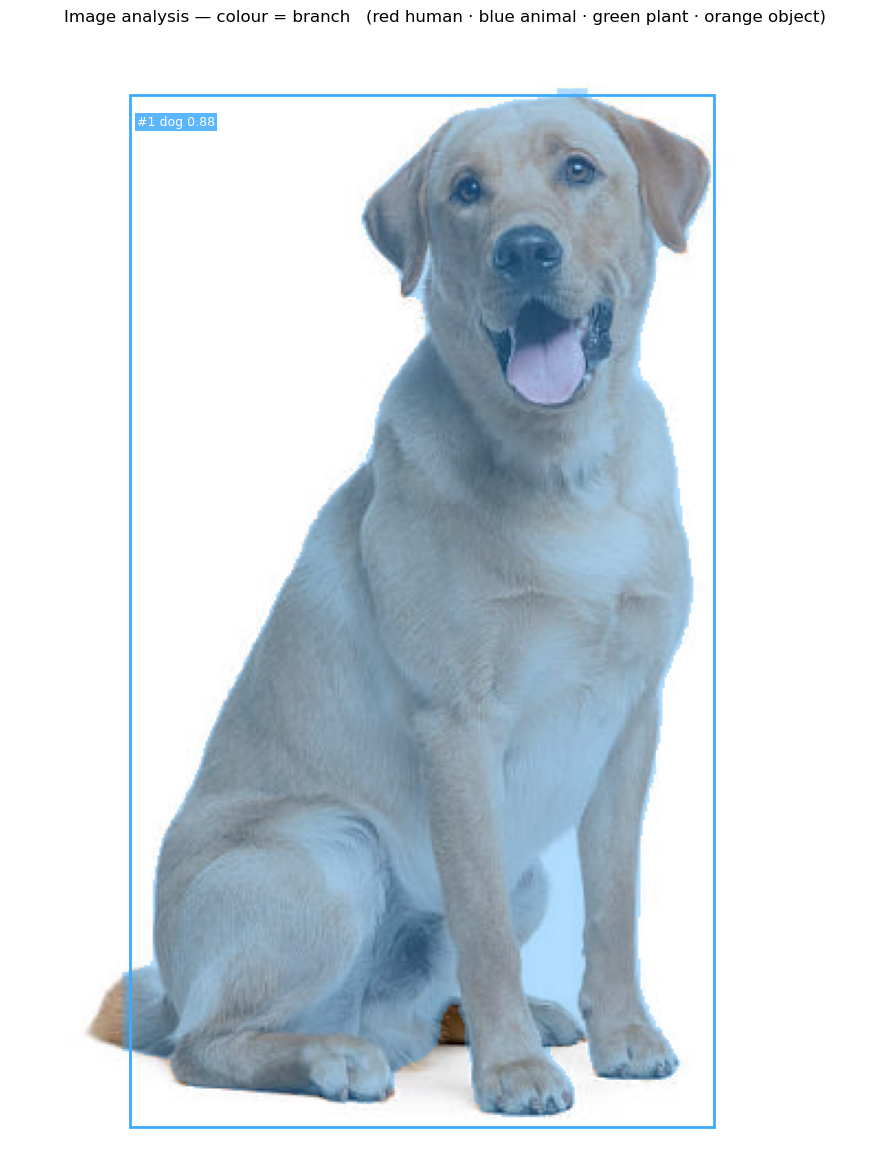

 #  label                  conf  category → branch
 1  dog                    0.88  animal   → animal / plant construction (7 steps)


In [6]:
def analyse_scene(image):
    """Detect everything, merge the detectors, decide which drawing branch each subject gets."""
    h, w = image.shape[:2]
    A = float(h * w)
    t0 = time.time()
    coco = run_seg(image)
    poses = run_pose(image)
    faces = run_faces(image) if DETECT_FACES else []
    extra = run_open_vocab(image) if USE_OPEN_VOCAB else []

    items: List[Item] = []
    used = set()
    seg_people = [(i, s) for i, s in enumerate(coco) if s.category == "human"]

    # people come from the POSE model (it has the joints); borrow the mask from the matching segmentation
    for p in poses:
        it = Item("person", p["conf"], "human", p["box"], None, p["kp"], p["kpc"], source="pose")
        best, bi = 0.0, None
        for i, s in seg_people:
            v = box_iou(p["box"], s.box)
            if v > best:
                best, bi = v, i
        if bi is not None and best > 0.4:
            it.mask = coco[bi].mask
            used.add(bi)
        items.append(it)

    for i, s in enumerate(coco):
        if i in used:
            continue
        if s.category == "human":                           # a person the pose model could not read
            s.label, s.category, s.note = "person (no pose)", "object", "pose not found → basic shapes"
        items.append(s)

    # optional open-vocabulary results: add new things, or relabel a COCO guess when they agree on the same mask
    for e in extra:
        clash = [x for x in items if x.category != "human" and (mask_iou(x.mask, e.mask) > 0.5 or box_iou(x.box, e.box) > 0.6)]
        if clash:
            x = clash[0]
            if e.conf >= x.conf:
                x.label, x.category, x.conf, x.source, x.note = e.label, e.category, e.conf, "open-vocab", f"relabelled from COCO"
            continue
        items.append(e)

    items = [x for x in items if x.box_area >= MIN_ITEM_FRAC * A]
    items.sort(key=lambda x: x.box_area, reverse=True)
    items = items[:MAX_ITEMS]

    # attach faces to people (or create a stand-alone face item)
    people = [x for x in items if x.category == "human" and x.kp is not None]
    for f in faces:
        c = f.mean(0)
        cand = [x for x in people if x.box[0] <= c[0] <= x.box[2] and x.box[1] <= c[1] <= x.box[3] and x.face is None]
        if cand:                                            # the person whose nose is closest to the face centre
            def d_nose(x):
                return np.linalg.norm(x.kp[0] - c) if x.kpc[0] > 0.3 else 1e9
            min(cand, key=d_nose).face = f
        else:
            bx = (float(f[:, 0].min()), float(f[:, 1].min()), float(f[:, 0].max()), float(f[:, 1].max()))
            items.append(Item("face", 1.0, "human", bx, face=f, source="face"))

    for k, it in enumerate(items, 1):
        it.idx = k
        if it.category == "human":
            if it.kp is not None:
                it.routes.append("body")
            if it.face is not None:
                it.routes.append("face")
        elif it.category in ("animal", "plant"):
            it.routes.append("creature")
        else:
            it.routes.append("shapes")
    print(f"Analysis finished in {time.time() - t0:.1f}s  →  {len(items)} subject(s)")
    return items


ROUTE_TEXT = {"body": "human BODY geometry (7 steps)", "face": "human FACE landmarks (9 steps)",
              "creature": "animal / plant construction (7 steps)", "shapes": "GEOMETRIC SHAPES via SAM + multi-primitive (9-12 steps)"}
CAT_COLOR = {"human": (255, 80, 80), "animal": (60, 170, 255), "plant": (60, 200, 90), "object": (255, 170, 40)}


def show_analysis(image, items):
    """The first thing to check: did the detectors see what you expected?"""
    over = image.astype(np.float32).copy()
    for it in items:
        if it.mask is not None:
            over[it.mask] = over[it.mask] * 0.6 + np.array(CAT_COLOR[it.category], np.float32) * 0.4
    fig, ax = plt.subplots(figsize=(9, 9 * image.shape[0] / image.shape[1] + 0.8))
    ax.imshow(over.astype(np.uint8)); ax.axis("off")
    for it in items:
        x0, y0, x1, y1 = it.box
        col = np.array(CAT_COLOR[it.category]) / 255
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2))
        ax.text(x0 + 3, y0 + 14, f"#{it.idx} {it.label} {it.conf:.2f}", color="white", fontsize=9,
                bbox=dict(facecolor=col, alpha=0.85, pad=1.5, lw=0))
        if it.face is not None:
            ax.scatter(it.face[:, 0], it.face[:, 1], s=4, c="yellow")
        if it.kp is not None:
            ok = it.kpc > 0.3
            ax.scatter(it.kp[ok, 0], it.kp[ok, 1], s=10, c="lime", edgecolors="black", linewidths=0.4)
    ax.set_title("Image analysis — colour = branch   (red human · blue animal · green plant · orange object)")
    plt.tight_layout(); plt.show()
    print(f"{'#':>2}  {'label':<22}{'conf':>5}  {'category':<8} → branch")
    for it in items:
        print(f"{it.idx:>2}  {it.label:<22}{it.conf:>5.2f}  {it.category:<8} → " + " + ".join(ROUTE_TEXT[r] for r in it.routes)
              + (f"   [{it.note}]" if it.note else ""))
    if not items:
        print("Nothing recognised → the whole-picture SHAPE MAP (section 10) will still give you basic shapes.")


items = analyse_scene(img)
show_analysis(img, items)

## 6. Branch A — Human BODY (7 construction steps)
`head + guides → neck + shoulders → ribcage + waist → pelvis + hips → limb skeleton → joints + volumes → hands + feet`

**Corrections over the original body notebook**
* Head size comes from **torso length** (shoulder width collapses in a side view) — or from the 68 face landmarks when a face was found.
* Side view is detected from `shoulder width ÷ torso length`; ribcage / pelvis **depth** is then measured on the person mask **perpendicular to the spine** (not along a pixel row that includes the arms) and clamped to sane limits.
* In a side view the **far-side arm and leg are drawn dashed / thin**, instead of two identical limbs on top of each other.
* Missing joints are never invented. If hips are not visible the notebook automatically switches to an **upper-body** drawing.
* Limbs are rounded tapered capsules whose width scales with the limb's own length.

In [7]:
KP = dict(nose=0, leye=1, reye=2, lear=3, rear=4, ls=5, rs=6, le=7, re=8, lw=9, rw=10,
          lh=11, rh=12, lk=13, rk=14, la=15, ra=16)


def measure_width(mask, p, n, max_len):
    """Length of mask pixels through point p along ±n (0 if p is outside the mask)."""
    if mask is None:
        return 0
    h, w = mask.shape

    def march(sign):
        for i in range(1, int(max_len)):
            x = int(round(p[0] + sign * n[0] * i)); y = int(round(p[1] + sign * n[1] * i))
            if not (0 <= x < w and 0 <= y < h) or not mask[y, x]:
                return i - 1
        return int(max_len)

    x, y = int(round(p[0])), int(round(p[1]))
    if not (0 <= x < w and 0 <= y < h) or not mask[y, x]:
        return 0
    return march(1) + march(-1)


def face_head_geometry(lm):
    """Head oval + face frame from 68 landmarks (used by the face branch AND the body's head)."""
    L = np.asarray(lm, float)
    le, re_ = L[36:42].mean(0), L[42:48].mean(0)
    eye_mid = (le + re_) / 2
    jaw_span = L[16] - L[0]
    u = unit(re_ - le) if np.linalg.norm(re_ - le) > 0.12 * np.linalg.norm(jaw_span) else unit(jaw_span)
    v = np.array([-u[1], u[0]])                       # "down" in the face's own frame

    def loc(p):
        return np.array([np.dot(p - eye_mid, u), np.dot(p - eye_mid, v)])

    def img_pt(x, y):
        return eye_mid + x * u + y * v

    J = np.array([loc(p) for p in L[0:17]])
    chin_y = J[8, 1]
    brow_y = float(np.mean([loc(p)[1] for p in L[17:27]]))
    nose_base_y = float(np.mean([loc(p)[1] for p in L[31:36]]))
    cx = (J[:, 0].min() + J[:, 0].max()) / 2           # centre from the JAW EXTREMES (fixes the off-centre oval)
    fw = float(J[:, 0].max() - J[:, 0].min())
    y_top = brow_y - 0.60 * (chin_y - brow_y)          # skull top is not a landmark → construction estimate
    cy = (y_top + chin_y) / 2
    semi_h = (chin_y - y_top) / 2 * 1.03
    semi_w = fw / 2 * 1.04
    return dict(L=L, u=u, v=v, eye_mid=eye_mid, loc=loc, img_pt=img_pt, J=J, cx=cx, cy=cy, fw=fw,
                chin_y=chin_y, brow_y=brow_y, nose_base_y=nose_base_y, y_top=y_top, semi_h=semi_h, semi_w=semi_w,
                centre=img_pt(cx, cy), angle=ang_deg(v))


def build_body_sketch(item, th=0.30):
    """Returns (Sketch, info) or (None, reason)."""
    kp, kc = item.kp, item.kpc

    def P(name, t=th):
        i = KP[name]
        return kp[i].astype(float) if kc[i] >= t else None

    ls, rs = P("ls"), P("rs")
    if ls is None or rs is None:
        return None, "both shoulders are needed"
    sh = (ls + rs) / 2
    sw = float(np.linalg.norm(ls - rs))
    if sw < 4:
        return None, "person too small"

    lh, rh = P("lh"), P("rh")
    if lh is None and rh is not None:
        lh = rh.copy()
    if rh is None and lh is not None:
        rh = lh.copy()
    lower = lh is not None and rh is not None
    if lower:
        hip = (lh + rh) / 2
        t = float(np.linalg.norm(hip - sh))
        lower = t >= 0.35 * sw                          # hips "above" the shoulders = unreliable
    if lower:
        d = (hip - sh) / t
        hw_front = max(float(np.linalg.norm(lh - rh)), 0.6 * sw)
    else:                                               # upper-body picture: estimate the spine direction
        u0 = unit(rs - ls)
        d = np.array([-u0[1], u0[0]])
        if d[1] < 0:
            d = -d
        t = 1.2 * sw
        hip = sh + d * t
        hw_front = 0.8 * sw
    n = np.array([-d[1], d[0]])                          # across the body

    yaw = float(np.clip((sw / t - 0.25) / 0.45, 0, 1))   # 0 = pure side view … 1 = front
    side = yaw < 0.35
    view = "side" if side else ("three-quarter" if yaw < 0.8 else "front")
    nose = P("nose")
    facing = (1 if nose[0] > sh[0] else -1) if (side and nose is not None) else 0

    mask = item.mask

    def depth_at(frac, lo, hi, default):
        w = measure_width(mask, sh + d * frac * t, n, 0.9 * t)
        return float(np.clip(w, lo * t, hi * t)) if w > 0 else default * t

    depth_chest = depth_at(0.30, 0.26, 0.55, 0.40)
    depth_waist = depth_at(0.62, 0.22, 0.50, 0.34)
    depth_hip = depth_at(1.00, 0.24, 0.52, 0.36)
    rib_a = 0.30 * t
    rib_b = lerp(depth_chest / 2, 0.42 * sw, yaw)
    waist_half = lerp(depth_waist / 2, 0.30 * sw, yaw)
    pelvis_half = lerp(depth_hip / 2, max(0.52 * hw_front, 0.30 * sw), yaw)

    # ---------------- head ----------------
    if item.face is not None:
        g = face_head_geometry(item.face)
        hc, hd, semi_h, semi_w = g["centre"], g["v"], g["semi_h"], g["semi_w"]
        if np.dot(hd, d) < 0:
            hd = -hd
        head_src = "face landmarks"
    else:
        leye, reye, lear, rear = P("leye"), P("reye"), P("lear"), P("rear")
        hd = d
        hc = None
        if leye is not None and reye is not None and np.linalg.norm(leye - reye) > 0.10 * t:
            eu = unit(reye - leye)
            hv = np.array([-eu[1], eu[0]])
            if hv[1] < 0:
                hv = -hv
            if np.dot(hv, d) > math.cos(math.radians(35)):
                hd = hv
            hc = (leye + reye) / 2 + hd * 0.015 * t
        elif nose is not None:
            hc = nose - d * 0.02 * t
        if hc is None or not (0.25 * t <= np.linalg.norm(hc - sh) <= 0.65 * t):
            hc = sh - d * 0.40 * t                      # sane default when the keypoints are odd / missing
        semi_h, semi_w = 0.215 * t, 0.155 * t
        if lear is not None and rear is not None and np.linalg.norm(lear - rear) > 0.10 * t:
            semi_w = float(np.clip(0.6 * np.linalg.norm(lear - rear), 0.11 * t, 0.19 * t))
        if side:
            semi_w = 0.165 * t
        head_src = "pose keypoints"
    hn = np.array([-hd[1], hd[0]])
    head_full = 2 * semi_h

    # ---------------- far side (side view only) ----------------
    far = None
    if side:
        if facing != 0:
            far = "l" if facing > 0 else "r"            # facing right → person's LEFT side is away from the camera
        else:
            mc = lambda ids: float(np.mean([kc[i] for i in ids]))
            far = "l" if mc([5, 7, 9, 11, 13, 15]) < mc([6, 8, 10, 12, 14, 16]) else "r"

    arms = {"l": [ls, P("le"), P("lw")], "r": [rs, P("re"), P("rw")]}
    legs = {"l": [lh, P("lk"), P("la")], "r": [rh, P("rk"), P("ra")]} if lower else {"l": [None] * 3, "r": [None] * 3}

    sk = Sketch("body")

    # ---- STEP 1 head + guides
    sk.next_step("Head + guides")
    sk.ellipse(hc, semi_h, semi_w, ang_deg(hd), "main")
    sk.line(hc - hd * semi_h * 1.15, hc + hd * semi_h * 1.15, "guide")
    sk.line(hc - hn * semi_w * 1.15, hc + hn * semi_w * 1.15, "guide")
    sk.poly([hc, sh, hip], "guide")

    # ---- STEP 2 neck + shoulders
    sk.next_step("Neck + shoulders")
    neck_top = hc + hd * semi_h * 0.90
    neck_base = sh - d * 0.015 * t
    nt, nb = 0.52 * semi_w, 0.62 * semi_w + 0.02 * sw
    for s_ in (-1, 1):
        sk.line(neck_top + hn * s_ * nt, neck_base + n * s_ * nb, "main")
    if yaw > 0.35:                                       # trapezius slope to each shoulder
        sk.line(neck_base - n * nb, ls if np.dot(ls - sh, n) < 0 else rs, "main")
        sk.line(neck_base + n * nb, rs if np.dot(rs - sh, n) > 0 else ls, "main")
    sk.line(ls, rs, "main")
    sk.dot(ls, "main"); sk.dot(rs, "main")

    # ---- STEP 3 ribcage + waist
    sk.next_step("Ribcage + waist")
    sk.ellipse(sh + d * 0.30 * t, rib_a, rib_b, ang_deg(d), "main")
    waist_c = sh + d * 0.64 * t
    sk.line(waist_c - n * waist_half, waist_c + n * waist_half, "main")
    sk.line(sh, hip, "guide")

    # ---- STEP 4 pelvis + hips
    if lower:
        sk.next_step("Pelvis + hips")
        hip_n = hip + d * 0.14 * t
        sk.poly([waist_c - n * waist_half, waist_c + n * waist_half, hip + n * pelvis_half, hip_n + n * pelvis_half * 0.45,
                 hip_n - n * pelvis_half * 0.45, hip - n * pelvis_half], "main", closed=True)
        sk.line(hip - n * pelvis_half, hip + n * pelvis_half, "guide")
        for hp in (lh, rh):
            sk.circle(hp, 0.035 * t, "thin")

    # ---- STEP 5 limb skeleton
    sk.next_step("Limb skeleton")

    def stick(chain, is_far):
        pts = [p for p in chain]
        for a_, b_ in zip(pts[:-1], pts[1:]):
            if a_ is not None and b_ is not None:
                sk.line(a_, b_, "thin" if is_far else "main", dash=is_far)

    for s_ in ("l", "r"):
        stick(arms[s_], far == s_)
        stick(legs[s_], far == s_)

    # ---- STEP 6 joints + volumes
    sk.next_step("Joints + volumes")
    specs = [(0.13, 0.095), (0.095, 0.06)]                 # arm: upper arm, forearm   (start, end radius ÷ length)
    specs_leg = [(0.15, 0.10), (0.10, 0.065)]
    for s_ in ("l", "r"):
        for chain, sp in ((arms[s_], specs), (legs[s_], specs_leg)):
            for (a_, b_), (r1, r2) in zip(zip(chain[:-1], chain[1:]), sp):
                if a_ is None or b_ is None:
                    continue
                Lseg = float(np.linalg.norm(b_ - a_))
                if Lseg < 4:
                    continue
                sk.capsule(a_, r1 * Lseg, b_, r2 * Lseg, "thin" if far == s_ else "main")
            for p_ in chain:
                sk.circle(p_, 0.03 * t, "thin")

    # ---- STEP 7 hands + feet
    sk.next_step("Hands + feet")
    hl = 0.75 * head_full
    for s_ in ("l", "r"):
        sh_, el_, wr_ = arms[s_]
        if el_ is not None and wr_ is not None:
            hdir = unit(wr_ - el_); hnrm = np.array([-hdir[1], hdir[0]])
            sk.poly([wr_ - hnrm * 0.20 * hl, wr_ + hdir * 0.55 * hl - hnrm * 0.27 * hl, wr_ + hdir * hl - hnrm * 0.13 * hl,
                     wr_ + hdir * hl + hnrm * 0.13 * hl, wr_ + hdir * 0.55 * hl + hnrm * 0.27 * hl, wr_ + hnrm * 0.20 * hl],
                    "thin" if far == s_ else "main", closed=True)
        hp_, kn_, an_ = legs[s_]
        if an_ is not None:
            fl = head_full * (1.0 if side else 0.55)
            if side:
                f = facing if facing != 0 else 1
                sk.poly([an_ + np.array([-0.25 * fl * f, 0.30 * fl]), an_ + np.array([0.95 * fl * f, 0.30 * fl]),
                         an_ + np.array([0.80 * fl * f, 0.12 * fl]), an_ + np.array([0.10 * fl * f, -0.05 * fl]),
                         an_ + np.array([-0.15 * fl * f, -0.05 * fl])], "thin" if far == s_ else "main", closed=True)
            else:
                out = 1 if np.dot(an_ - hip, n) >= 0 else -1          # toes splay slightly outward
                tc = an_ + d * 0.60 * fl + n * 0.10 * fl * out
                sk.poly([an_ - n * 0.17 * fl, an_ + n * 0.17 * fl, tc + n * 0.28 * fl, tc - n * 0.28 * fl], "main", closed=True)

    info = dict(view=view, lower=lower, head_source=head_src, far=far, yaw=round(yaw, 2))
    return sk, info

## 7. Branch B — Human FACE (9 steps from 68 landmarks)
`head oval → guide lines → eyes → nose → mouth → jaw + ears → brows + hair guide → clean line art → shading`

**Corrections over the original face notebook (V3)**
* The head oval is centred on the **jaw extremes** (the old oval drifted sideways when the face was turned, so the jaw poked out of it).
* Ears are placed **on the oval's edge** between the *brow line* and the *nose-base line* (the classical proportion) — before they floated beside the jaw.
* The clean sketch now has a **closed head outline**: cranium arc joined to the real jaw line (before the hair arc stopped short and left a gap).
* Guide lines follow the face's own tilt and add the **brow / nose-base thirds**, plus a curved centre line that follows the nose and lips.
* Shading is a **smooth 4-tone value map** (percentile split + median filter) restricted to the head outline, instead of a speckled 5-level posterise.

In [8]:
def build_face_sketch(image, lm):
    g = face_head_geometry(lm)
    L, img_pt, J = g["L"], g["img_pt"], g["J"]
    cx, cy, semi_h, semi_w = g["cx"], g["cy"], g["semi_h"], g["semi_w"]
    y_top, chin_y, brow_y, nb_y, ang = g["y_top"], g["chin_y"], g["brow_y"], g["nose_base_y"], g["angle"]

    jaw, lbrow, rbrow = L[0:17], L[17:22], L[22:27]
    nose_bridge, nose_bottom = L[27:31], L[31:36]
    leye, reye, outer, inner = L[36:42], L[42:48], L[48:60], L[60:68]

    def chord(y):                                        # half-width of the head oval at height y
        return semi_w * math.sqrt(max(0.0, 1 - ((y - cy) / semi_h) ** 2))

    def cranium_arc(sx=1.0, sy=1.0, n=60, y_end=None):   # oval arc from one side over the top to the other
        yl, yr = (J[0, 1], J[16, 1]) if y_end is None else (y_end, y_end)
        sL = float(np.clip((yl - cy) / (sy * semi_h), -0.95, 0.95))
        sR = float(np.clip((yr - cy) / (sy * semi_h), -0.95, 0.95))
        ts = np.linspace(math.pi - math.asin(sL), 2 * math.pi + math.asin(sR), n)
        return [img_pt(cx + sx * semi_w * math.cos(t), cy + sy * semi_h * math.sin(t)) for t in ts]

    ear_cy = (brow_y + nb_y) / 2
    ear_h = (nb_y - brow_y) * 1.0
    ear_w = 0.42 * ear_h
    k_ear = math.sqrt(max(0.0, 1 - ((ear_cy - cy) / semi_h) ** 2))
    ears = [img_pt(cx + sg * semi_w * k_ear + sg * ear_w * 0.28, ear_cy) for sg in (-1, 1)]

    def eye(sk, pts, style="main"):
        sk.poly(pts, style, closed=True)
        c = pts.mean(0); w = np.linalg.norm(pts[3] - pts[0])
        sk.dot(c, style, r=0.10 * w)

    sk = Sketch("face")
    sk.margin = 0.06

    sk.next_step("Head oval")
    sk.ellipse(g["centre"], semi_h, semi_w, ang, "main")

    sk.next_step("Guide lines")
    sk.poly([img_pt(cx, y_top), L[27], L[30], L[33], L[51], L[57], L[8]], "guide")          # centre line follows the face
    for y in (0.0, brow_y, nb_y, brow_y - 0.5 * (chin_y - brow_y)):                          # eye · brow · nose-base · hairline
        hw = chord(y)
        sk.line(img_pt(cx - hw, y), img_pt(cx + hw, y), "guide")

    sk.next_step("Eyes")
    eye(sk, leye); eye(sk, reye)

    sk.next_step("Nose")
    sk.poly(nose_bridge, "main")
    sk.poly(nose_bottom, "main")
    sk.line(L[30], L[31], "thin"); sk.line(L[30], L[35], "thin")

    sk.next_step("Mouth")
    sk.poly(outer, "main", closed=True)
    sk.poly(inner, "thin", closed=True)

    sk.next_step("Jaw + ears")
    sk.poly(jaw, "main")
    for e in ears:
        sk.ellipse(e, ear_h / 2, ear_w / 2, ang, "thin")

    sk.next_step("Brows + hair guide")
    sk.poly(lbrow, "main"); sk.poly(rbrow, "main")
    sk.poly(cranium_arc(1.10, 1.06, y_end=brow_y), "thin")

    # clean line art = every stroke you keep, no construction guides, one closed head outline
    sk.next_step("Clean line art"); sk.solo.add(sk.step)
    sk.poly(cranium_arc() + list(jaw[::-1]), "main", closed=True)
    sk.poly(lbrow, "main"); sk.poly(rbrow, "main")
    eye(sk, leye); eye(sk, reye)
    sk.poly(nose_bridge, "thin"); sk.poly(nose_bottom, "main")
    sk.poly(outer, "main", closed=True); sk.poly(inner, "thin", closed=True)
    for e in ears:
        sk.ellipse(e, ear_h / 2, ear_w / 2, ang, "thin")
    sk.poly(cranium_arc(1.10, 1.06, y_end=brow_y), "thin")

    # ---- step 9: smooth 4-tone value map inside the head outline ----
    ox, oy, s, cw, ch = sk.frame()
    gray = cv2.cvtColor(sk.warp(image), cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (0, 0), max(1.5, 0.022 * g["fw"] * s))
    region = np.zeros((ch, cw), np.uint8)
    cv2.fillPoly(region, [np.array([sk.P(p) for p in (cranium_arc() + list(jaw[::-1]))], np.int32)], 255)
    region = cv2.erode(region, np.ones((3, 3), np.uint8), iterations=2)
    yy, xx = np.mgrid[0:ch, 0:cw]                                   # keep only skin below the hairline guide
    src = np.stack([xx / s + ox, yy / s + oy], -1) - g["eye_mid"]
    region[(src @ g["v"]) < (brow_y - 0.5 * (chin_y - brow_y)) + 0.02 * (chin_y - brow_y)] = 0
    vals = gray[region > 0]
    if vals.size > 50:
        q = np.digitize(gray, np.percentile(vals, [25, 52, 80]))
        tone = np.array([85, 145, 200, 250], np.uint8)[q]
        k = int(max(5, round(0.03 * g["fw"] * s)) // 2 * 2 + 1)
        tone = cv2.medianBlur(cv2.medianBlur(tone, k), k)
        shade = np.full((ch, cw), 255, np.uint8)
        shade[region > 0] = tone[region > 0]
        shade = np.minimum(cv2.cvtColor(shade, cv2.COLOR_GRAY2RGB), sk.render(only_step=sk.step))
    else:
        shade = sk.render(only_step=sk.step)
    return sk, dict(extra_panels=[("9. Shading (value map)", shade)], view="face", head_source="68 landmarks")

## 8. Branch C — ANIMAL / BIRD / PLANT construction (7 steps)
`proportion box → main body mass → volume circles → gesture (spine) line → limbs / neck / tail lines → simplified outline → final`
(for plants: `box → crown / flower mass → leaf volumes → trunk / stem → branches → outline → final`)

**Corrections over the original object notebook**
* The body ellipse was drawn with **1.6σ** half-axes (too small). It is now fitted on the *thick core* of the silhouette (the part that is not legs / neck / tail) and dilated back by the erosion radius, so it hugs the real torso.
* Every subject is **cropped and enlarged** — before, a small animal was a tiny drawing in a huge blank canvas.
* The skeleton is cleaned: the mask is smoothed first, the **longest skeleton path** becomes the gesture line, and only branches longer than 10 % of it become limb / tail lines. No more noisy spurs.
* Circles are numbered by size so a beginner knows which to draw first.
* *Honest limit:* this is a 2-D silhouette skeleton, not real anatomy — it will not find actual knees, shoulders or wings.

In [9]:
def clean_mask(m, close=5):
    """Close small gaps, fill holes, keep only the biggest blob."""
    u = np.asarray(m, bool).astype(np.uint8)
    u = cv2.morphologyEx(u, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close, close)))
    u = ndi.binary_fill_holes(u).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(u, 8)
    if n > 1:
        u = (lab == 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))).astype(np.uint8)
    return u.astype(bool)


def crop_to_mask(mask, pad_frac=0.04):
    ys, xs = np.nonzero(mask)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    pad = max(3, int(pad_frac * max(x1 - x0, y1 - y0)))
    x0, y0 = max(0, x0 - pad), max(0, y0 - pad)
    x1, y1 = min(mask.shape[1] - 1, x1 + pad), min(mask.shape[0] - 1, y1 + pad)
    return mask[y0:y1 + 1, x0:x1 + 1], int(x0), int(y0)


def longest_skeleton_path(sk):
    """Longest route through the skeleton (largest connected piece). Returns Nx2 (x, y) points."""
    lab, n = ndi.label(sk, structure=np.ones((3, 3)))
    if n == 0:
        return np.zeros((0, 2))
    sizes = ndi.sum(sk, lab, range(1, n + 1))
    comp = lab == (1 + int(np.argmax(sizes)))
    ys, xs = np.nonzero(comp)
    if len(xs) < 3:
        return np.zeros((0, 2))
    idx = {(int(y), int(x)): i for i, (y, x) in enumerate(zip(ys, xs))}
    pts = np.column_stack([xs, ys]).astype(float)
    adj = [[] for _ in range(len(xs))]
    for (y, x), i in idx.items():
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy or dx:
                    j = idx.get((y + dy, x + dx))
                    if j is not None:
                        adj[i].append(j)

    def bfs(src):
        par = {src: -1}; dq = deque([src]); last = src
        while dq:
            u = dq.popleft(); last = u
            for v in adj[u]:
                if v not in par:
                    par[v] = u; dq.append(v)
        return last, par

    a, _ = bfs(0)
    b, par = bfs(a)
    path = []; cur = b
    while cur != -1:
        path.append(pts[cur]); cur = par[cur]
    return np.array(path)


def smooth_path(p, k=9):
    if len(p) < k + 2:
        return p
    pad = k // 2
    q = np.vstack([np.repeat(p[:1], pad, 0), p, np.repeat(p[-1:], pad, 0)])
    ker = np.ones(k) / k
    out = np.column_stack([np.convolve(q[:, 0], ker, "valid"), np.convolve(q[:, 1], ker, "valid")])
    out[0], out[-1] = p[0], p[-1]
    return out


def simplify_path(p, eps):
    if len(p) < 3:
        return p
    return cv2.approxPolyDP(p.astype(np.float32).reshape(-1, 1, 2), eps, False).reshape(-1, 2)


def skeleton_branches(skel, main_path, min_len, max_branches=8):
    mp = np.zeros(skel.shape, np.uint8)
    for x, y in main_path.astype(int):
        mp[y, x] = 1
    rest = skel & ~(cv2.dilate(mp, np.ones((5, 5), np.uint8)) > 0)
    lab, n = ndi.label(rest, structure=np.ones((3, 3)))
    out = []
    for i in range(1, n + 1):
        comp = lab == i
        if comp.sum() < min_len:
            continue
        path = longest_skeleton_path(comp)
        if len(path) < min_len:
            continue
        ends = [path[0], path[-1]]
        j = int(np.argmin([np.min(np.linalg.norm(main_path - e, axis=1)) for e in ends]))
        e = ends[j]
        k = int(np.argmin(np.linalg.norm(main_path - e, axis=1)))
        ordered = path if j == 0 else path[::-1]                 # start at the end nearest the main line
        out.append(np.vstack([main_path[k], ordered]))
    out.sort(key=len, reverse=True)
    return out[:max_branches]


def volume_circles(m, dist, max_n, min_r_frac=0.07):
    """Greedy largest-inscribed circles (distance-transform maxima), numbered by size."""
    bs = max(m.shape)
    dd = dist.copy()
    circles = []
    for _ in range(max_n * 8):
        y, x = np.unravel_index(int(np.argmax(dd)), dd.shape)
        r = float(dd[y, x])
        if r < max(4.0, min_r_frac * bs):
            break
        circles.append((float(x), float(y), r))
        cv2.circle(dd, (int(x), int(y)), int(r * 1.15) + 1, 0, -1)
        if len(circles) >= max_n:
            break
    return circles


def core_ellipse(m, dist):
    """Torso-like ellipse: PCA of the thick core, grown back by the erosion radius."""
    dmax = float(dist.max())
    r0 = 0.45 * dmax
    ys, xs = np.nonzero(dist >= r0)
    if len(xs) < 12:
        ys, xs = np.nonzero(m); r0 = 0
    pts = np.column_stack([xs, ys]).astype(float)
    c = pts.mean(0)
    vals, vecs = np.linalg.eigh(np.cov(pts.T) + 1e-6 * np.eye(2))
    o = np.argsort(vals)[::-1]
    vals, vecs = vals[o], vecs[:, o]
    a = 2 * math.sqrt(max(vals[0], 1e-6)) + r0
    b = 2 * math.sqrt(max(vals[1], 1e-6)) + r0
    return c, a, max(b, 0.35 * dmax), ang_deg(vecs[:, 0])


def build_creature_sketch(item):
    kind = "plant" if item.category == "plant" else "animal"
    m, ox, oy = crop_to_mask(clean_mask(item.mask))
    S = lambda p: (float(p[0]) + ox, float(p[1]) + oy)
    h, w = m.shape
    bs = max(h, w)
    ys, xs = np.nonzero(m)
    bx0, by0, bx1, by1 = xs.min(), ys.min(), xs.max(), ys.max()
    dist = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 5)
    circles = volume_circles(m, dist, 4 if kind == "plant" else 6)
    smooth = cv2.GaussianBlur(m.astype(np.float32), (0, 0), max(1.5, 0.012 * bs)) > 0.5
    skel = skeletonize(smooth if smooth.sum() > 30 else m)
    main = smooth_path(longest_skeleton_path(skel), 9)
    main_s = simplify_path(main, max(1.5, 0.012 * bs)) if len(main) > 3 else main
    branches = []
    if len(main) > 8:
        branches = [simplify_path(smooth_path(b_, 7), max(1.5, 0.010 * bs))
                    for b_ in skeleton_branches(skel, main, min_len=max(8, int(0.10 * len(main))))]
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt = max(cnts, key=cv2.contourArea)
    outline = cv2.approxPolyDP(cnt, 0.012 * cv2.arcLength(cnt, True), True).reshape(-1, 2)
    ell = core_ellipse(m, dist) if kind == "animal" else None

    sk = Sketch("creature")

    sk.next_step("Proportion box")
    sk.poly([S((bx0, by0)), S((bx1, by0)), S((bx1, by1)), S((bx0, by1))], "main", closed=True)
    cx_, cy_ = (bx0 + bx1) / 2, (by0 + by1) / 2
    sk.line(S((cx_, by0)), S((cx_, by1)), "guide"); sk.line(S((bx0, cy_)), S((bx1, cy_)), "guide")
    sk.line(S((bx0, by0)), S((bx1, by1)), "guide"); sk.line(S((bx1, by0)), S((bx0, by1)), "guide")

    def put_circles(sel, style="main"):
        for i, (x, y, r) in sel:
            sk.circle(S((x, y)), r, style)
            sk.text(S((x - 0.18 * r, y + 0.18 * r)), str(i))

    if kind == "animal":
        sk.next_step("Main body mass")
        c, a, b, ang = ell
        sk.ellipse(S(c), a, b, ang, "main")
        sk.next_step("Volume circles (1 = biggest)")
        put_circles(list(enumerate(circles, 1)))
    else:
        sk.next_step("Crown / flower mass")
        put_circles(list(enumerate(circles[:1], 1)))
        sk.next_step("Leaf / petal volumes")
        put_circles(list(enumerate(circles, 1))[1:])

    sk.next_step("Gesture line (spine)" if kind == "animal" else "Trunk / stem line")
    if len(main_s) >= 2:
        sk.poly([S(p) for p in main_s], "main")
        sk.dot(S(main_s[0]), "main"); sk.dot(S(main_s[-1]), "main")

    sk.next_step("Legs · neck · tail lines" if kind == "animal" else "Branches")
    for b_ in branches:
        sk.poly([S(p) for p in b_], "main")

    sk.next_step("Simplified outline")
    sk.poly([S(p) for p in outline], "main", closed=True)
    for p in outline:
        sk.dot(S(p), "thin")

    sk.next_step("Final construction"); sk.solo.add(sk.step)
    if ell is not None:
        sk.ellipse(S(ell[0]), ell[1], ell[2], ell[3], "thin")
    for i, (x, y, r) in enumerate(circles, 1):
        sk.circle(S((x, y)), r, "thin")
    if len(main_s) >= 2:
        sk.poly([S(p) for p in main_s], "main")
    for b_ in branches:
        sk.poly([S(p) for p in b_], "main")
    sk.poly([S(p) for p in outline], "thin", closed=True)

    recipe = ([f"1. Draw a box with width : height = {(bx1 - bx0) / max(1, by1 - by0):.2f} : 1."]
              + ([f"2. Draw one big oval for the body, tilted about {(ell[3] + 90) % 180 - 90:.0f}°."] if ell else ["2. Draw the biggest circle for the crown / flower head."])
              + [f"3. Add {len(circles)} circles (head, chest, hips…) — start with the biggest.",
                 "4. Join them with one smooth gesture line.",
                 f"5. Add {len(branches)} extra lines for legs / neck / tail / branches.",
                 "6. Connect the outer corners with straight lines — that is your simplified outline."])
    return sk, dict(view=kind, recipe=recipe)

## 9. Branch D — GEOMETRIC SHAPES (SAM segments → multi-primitive reconstruction)
This branch now uses **your SAM + multi-primitive geometry code**. It is used for every object that is not a person / animal / plant, for anything the detectors do not know, and for the whole-picture shape map (section 10).

**Pipeline (from your notebook)**
1. **Segment everything** with SAM `SamAutomaticMaskGenerator` (your `mask_generator_2` settings). One pass per photo; the result is cached and shared by all objects.
2. **Colour the segments** (your `segmented_only` image): bigger segments are painted first, smaller ones on top, so every pixel belongs to exactly one part.
3. **Rebuild every part from basic shapes** — greedy, like your cells 39/43: at each round try *circle · ellipse · rectangle · square · triangle · line* at several sizes, keep the one that covers the most still-missing area while leaving the segment by ≤ `MAX_OUTSIDE_RATIO`; stop at `TARGET_COVERAGE` (80 %) or `MAX_SHAPES_PER_PART` (5).
4. **Black borders only**, overlapping borders stay visible. A colour-coded "typed" view shows which shape is which.
5. **Straight lines vs curves** (your cell 30 `trace_pieces`) for the object outline.

**Safety nets** (so the notebook never stops): official SAM → Ultralytics SAM → colour k-means regions (your first quantisation approach).
Everything is stored as vector shapes, so the SVG export contains real circles / ellipses / polygons.

In [10]:
# ───────────── single-shape fitting (used for the "main basic shape" step) ─────────────
def fit_primitive(m):
    """Best simple shape for a boolean mask → dict(kind, params, iou, centroid, area)."""
    u = m.astype(np.uint8)
    area = float(u.sum())
    cnts, _ = cv2.findContours(u, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts or area < 20:
        return None
    c = max(cnts, key=cv2.contourArea)
    if len(c) < 5:
        return None
    M = cv2.moments(u)
    cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]

    def iou(draw):
        t = np.zeros_like(u)
        draw(t)
        inter = np.logical_and(t > 0, u > 0).sum(); uni = np.logical_or(t > 0, u > 0).sum()
        return float(inter) / float(uni) if uni else 0.0

    cands = []
    r = math.sqrt(area / math.pi)
    cands.append(["circle", dict(c=(cx, cy), r=r), iou(lambda t: cv2.circle(t, (int(cx), int(cy)), int(r), 1, -1)), 0.02])
    (ex, ey), (MA, ma), an = cv2.fitEllipse(c)
    e_iou = iou(lambda t: cv2.ellipse(t, (int(ex), int(ey)), (max(1, int(MA / 2)), max(1, int(ma / 2))), an, 0, 360, 1, -1))
    if max(MA, ma) / max(1e-6, min(MA, ma)) < 1.12:
        e_iou -= 0.05                                                  # nearly round → prefer the circle
    cands.append(["ellipse", dict(c=(ex, ey), a=MA / 2, b=ma / 2, ang=an), e_iou, 0.01])
    (rcx, rcy), (rw, rh), rang = cv2.minAreaRect(c)
    box = cv2.boxPoints(((rcx, rcy), (rw, rh), rang))
    sq = rw > 0 and rh > 0 and max(rw, rh) / min(rw, rh) <= 1.2        # your square-vs-rectangle rule
    cands.append(["square" if sq else "rectangle", dict(pts=box.tolist()), iou(lambda t: cv2.fillPoly(t, [box.astype(np.int32)], 1)), 0.0])
    try:
        _, tri = cv2.minEnclosingTriangle(c)
        tri = tri.reshape(-1, 2)
        cands.append(["triangle", dict(pts=tri.tolist()), iou(lambda t: cv2.fillPoly(t, [tri.astype(np.int32)], 1)), -0.02])
    except Exception:
        pass
    best = max(cands, key=lambda k: k[2] + k[3])
    return dict(kind=best[0], params=best[1], iou=best[2], centroid=(cx, cy), area=area)


def draw_prim(sk, prim, S=lambda p: p, style="main", scale=1.0):
    """Add a fitted primitive (from fit_primitive) to a Sketch."""
    if prim is None:
        return
    k, p = prim["kind"], prim["params"]
    if k == "circle":
        sk.circle(S(p["c"]), p["r"] * scale, style, tag=k)
    elif k == "ellipse":
        sk.ellipse(S(p["c"]), p["a"] * scale, p["b"] * scale, p["ang"], style, tag=k)
    else:
        sk.poly([S(q) for q in p["pts"]], style, closed=True, tag=k)


# ───────────── fallback part-splitters (used only if SAM gives nothing for an object) ─────────────
def split_parts(m, max_parts=6, min_frac=0.05):
    d = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 5)
    if d.max() < 4:
        return [m]
    peaks = peak_local_max(d, min_distance=max(6, int(0.12 * max(m.shape))), threshold_abs=0.40 * d.max(),
                           labels=m.astype(np.uint8), exclude_border=False)
    if len(peaks) < 2:
        return [m]
    markers = np.zeros(m.shape, np.int32)
    for i, (y, x) in enumerate(peaks[:max_parts * 2], 1):
        markers[y, x] = i
    ws = watershed(-d, markers, mask=m)
    parts = [ws == i for i in range(1, markers.max() + 1) if (ws == i).sum() >= min_frac * m.sum()]
    parts.sort(key=lambda p: -p.sum())
    return parts[:max_parts] or [m]


def split_by_color(m, rgb, K=3, min_frac=0.08):
    pts = rgb[m].astype(np.float32)
    if len(pts) < 200:
        return [m]
    lab = cv2.cvtColor(pts.reshape(-1, 1, 3).astype(np.uint8), cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float32)
    _, lbl, _ = cv2.kmeans(lab, K, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 15, 1.0), 2, cv2.KMEANS_PP_CENTERS)
    lbl = lbl.flatten()
    parts = []
    for k in range(K):
        pm = np.zeros(m.shape, np.uint8)
        pm[m] = (lbl == k).astype(np.uint8)
        pm = cv2.morphologyEx(pm, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
        n, cc, st, _ = cv2.connectedComponentsWithStats(pm, 8)
        if n > 1:
            j = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
            if st[j, cv2.CC_STAT_AREA] >= min_frac * m.sum():
                parts.append(ndi.binary_fill_holes(cc == j))
    parts.sort(key=lambda p: -p.sum())
    return parts or [m]

### 9a. Segment everything (SAM) → coloured parts → components

In [11]:
import urllib.request

SAM_URLS = {"vit_h": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth",
            "vit_l": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth",
            "vit_b": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"}
_sam_gen = None


def sam_official_segments(image):
    """Meta's SamAutomaticMaskGenerator with your `mask_generator_2` settings."""
    global _sam_gen
    from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
    if _sam_gen is None:
        SAM_CHECKPOINT_DIR.mkdir(exist_ok=True)
        ckpt = SAM_CHECKPOINT_DIR / SAM_URLS[SAM_MODEL_TYPE].split("/")[-1]
        if not ckpt.exists():
            print(f"Downloading SAM {SAM_MODEL_TYPE} checkpoint (one time) …")
            urllib.request.urlretrieve(SAM_URLS[SAM_MODEL_TYPE], ckpt)
        sam = sam_model_registry[SAM_MODEL_TYPE](checkpoint=str(ckpt))
        sam.to(device=DEVICE); sam.eval()
        _sam_gen = SamAutomaticMaskGenerator(model=sam, points_per_side=32, pred_iou_thresh=0.86, stability_score_thresh=0.92,
                                             crop_n_layers=1, crop_n_points_downscale_factor=2, min_mask_region_area=100)
    return _sam_gen.generate(image)                       # RGB uint8, list of dicts with 'segmentation', 'area' …


def sam_ultralytics_segments(image):
    """Segment-everything with the Ultralytics SAM wrapper (no extra package needed)."""
    from ultralytics import SAM
    h, w = image.shape[:2]
    r = SAM("sam_b.pt")(_bgr(image), verbose=False, device=DEVICE)[0]
    if r.masks is None:
        return []
    out = []
    for mk in r.masks.data.cpu().numpy():
        if mk.shape != (h, w):
            mk = cv2.resize(mk.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
        mk = mk > 0
        out.append(dict(segmentation=mk, area=int(mk.sum())))
    return out


def kmeans_segments(image, K=None):
    """Your first approach: quantise colours, every colour patch is a region.
    Flat / cartoon pictures keep your K=16; real photos get fewer clusters + smoothing so they are not shredded."""
    h, w = image.shape[:2]
    sc = min(1.0, 640 / max(h, w))
    small = cv2.resize(image, (max(1, int(w * sc)), max(1, int(h * sc))), interpolation=cv2.INTER_AREA)
    sh, sw = small.shape[:2]
    flat = len(np.unique((small // 8).reshape(-1, 3), axis=0)) < 250          # few distinct colours → drawing / cartoon
    if K is None:
        K = 16 if flat else 7
    min_ratio = 0.0008 if flat else 0.006
    if not flat:
        small = cv2.bilateralFilter(cv2.bilateralFilter(small, 9, 50, 50), 9, 50, 50)
    Z = small.reshape(-1, 3).astype(np.float32)
    _, labels, _ = cv2.kmeans(Z, K, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3, cv2.KMEANS_PP_CENTERS)
    labels = labels.reshape(sh, sw)
    out = []
    for k in range(K):
        mk = cv2.morphologyEx((labels == k).astype(np.uint8) * 255, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)), iterations=2)
        mk = cv2.morphologyEx(mk, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=1 if flat else 2)
        n, cc, st, _ = cv2.connectedComponentsWithStats(mk, 8)
        for j in range(1, n):
            if st[j, cv2.CC_STAT_AREA] >= min_ratio * sh * sw:
                big = cv2.resize((cc == j).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST) > 0
                out.append(dict(segmentation=big, area=int(big.sum())))
    return out


def _compute_segments(image):
    h, w = image.shape[:2]
    order = {"auto": ["sam_official", "sam_ultralytics", "kmeans"]}.get(SEGMENT_ENGINE, [SEGMENT_ENGINE, "kmeans"])
    fn = {"sam_official": sam_official_segments, "sam_ultralytics": sam_ultralytics_segments, "kmeans": kmeans_segments}
    segs, used = [], None
    print("Segmenting the whole picture (this can take a while on CPU — use SAM_MODEL_TYPE='vit_b' to speed up) …")
    for name in order:
        try:
            segs = fn[name](image)
            if segs:
                used = name
                break
            print(f"  {name}: no masks")
        except Exception as e:
            print(f"  {name} unavailable → {type(e).__name__}: {str(e)[:110]}")
    segs = [s for s in segs if 0 < s["area"] <= MAX_REGION_AREA_RATIO * h * w or used == "kmeans"]
    # painted large → small so every pixel keeps its smallest segment (your `segmented_only` construction)
    lab = np.zeros((h, w), np.int32)
    for i, s in enumerate(sorted(segs, key=lambda x: -x["area"]), 1):
        lab[s["segmentation"]] = i
    rng = np.random.default_rng(42)
    colors = rng.integers(50, 256, size=(len(segs) + 1, 3), dtype=np.uint8)
    colors[0] = 0
    seg_rgb = colors[lab]
    comps = []
    for i, sl in enumerate(ndi.find_objects(lab), 1):
        if sl is None:
            continue
        sub = (lab[sl] == i).astype(np.uint8)
        n, cc, st, _ = cv2.connectedComponentsWithStats(sub, connectivity=8)
        for j in range(1, n):
            a = int(st[j, cv2.CC_STAT_AREA])
            if a < MIN_COMPONENT_AREA or a > MAX_REGION_AREA_RATIO * h * w:
                continue
            comp = ndi.binary_fill_holes(cc == j)               # solid part (inner holes are other segments)
            comps.append(dict(mask=comp, ox=int(sl[1].start), oy=int(sl[0].start), area=int(comp.sum()), color=tuple(int(v) for v in colors[i])))
    comps.sort(key=lambda c: -c["area"])
    comps = comps[:MAX_COMPONENTS]
    print(f"Segmentation engine: {used or 'none'}  →  {len(segs)} masks → {len(comps)} parts")
    return dict(engine=used, lab=lab, seg_rgb=seg_rgb, comps=comps)


_SEG = {}


def get_segments(image):
    key = (image.shape, hash(image[::29, ::29].tobytes()))
    if key not in _SEG:
        _SEG.clear()
        _SEG[key] = _compute_segments(image)
    return _SEG[key]

### 9b. Greedy multi-primitive reconstruction (your cells 39 / 43, now producing vector shapes)

In [12]:
def _mk(shape, draw):
    m = np.zeros(shape, np.uint8)
    draw(m)
    return m


def generate_candidates(residual):
    """Candidate shapes (several sizes each) for the biggest piece of what is still missing."""
    shape = residual.shape
    out = []
    cnts, _ = cv2.findContours(residual, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts:
        return out
    cnt = max(cnts, key=cv2.contourArea)
    if cv2.contourArea(cnt) < 10:
        return out

    dist = cv2.distanceTransform(residual, cv2.DIST_L2, 5)                       # circles from the distance transform
    _, rmax, _, (cx, cy) = cv2.minMaxLoc(dist)
    if rmax >= 2:
        for sc in (1.0, 0.9, 0.8, 0.7, 0.6):
            r = int(rmax * sc)
            if r >= 2:
                out.append(("circle", _mk(shape, lambda m: cv2.circle(m, (cx, cy), r, 255, -1)), dict(c=(cx, cy), r=r)))

    if len(cnt) >= 5:                                                             # ellipses
        (ex, ey), (d1, d2), ang = cv2.fitEllipse(cnt)
        for sc in (0.95, 0.85, 0.75, 0.65, 0.55):
            a, b = max(1, int(d1 * sc / 2)), max(1, int(d2 * sc / 2))
            out.append(("ellipse", _mk(shape, lambda m: cv2.ellipse(m, (int(ex), int(ey)), (a, b), float(ang), 0, 360, 255, -1)),
                        dict(c=(ex, ey), a=a, b=b, ang=float(ang))))

    (rcx, rcy), (rw, rh), rang = cv2.minAreaRect(cnt)                             # rectangles / squares
    if rw > 2 and rh > 2:
        name = "square" if max(rw, rh) / min(rw, rh) < 1.20 else "rectangle"
        for sc in (0.95, 0.85, 0.75, 0.65, 0.55, 0.45):
            box = cv2.boxPoints(((rcx, rcy), (max(2.0, rw * sc), max(2.0, rh * sc)), rang))
            out.append((name, _mk(shape, lambda m: cv2.fillPoly(m, [np.int32(box)], 255)), dict(pts=box.tolist())))

    try:                                                                          # triangles
        ta, tri = cv2.minEnclosingTriangle(cnt)
        if tri is not None and ta > 0:
            tri = tri.reshape(3, 2).astype(np.float32)
            c0 = tri.mean(0)
            for sc in (0.95, 0.85, 0.75, 0.65, 0.55, 0.45):
                pts = c0 + (tri - c0) * sc
                out.append(("triangle", _mk(shape, lambda m: cv2.fillPoly(m, [np.int32(pts)], 255)), dict(pts=pts.tolist())))
    except cv2.error:
        pass

    bx, by, bw, bh = cv2.boundingRect(cnt)                                        # lines for long thin parts
    if max(bw, bh) / max(1, min(bw, bh)) > 2.3:
        pts = cnt.reshape(-1, 2).astype(np.float32)
        vx, vy, x0, y0 = [float(v[0]) for v in cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01)]
        proj = (pts[:, 0] - x0) * vx + (pts[:, 1] - y0) * vy
        p1 = (int(x0 + proj.min() * vx), int(y0 + proj.min() * vy))
        p2 = (int(x0 + proj.max() * vx), int(y0 + proj.max() * vy))
        for ts in (0.75, 0.55, 0.40):
            t = max(2, int(min(bw, bh) * ts))
            out.append(("line", _mk(shape, lambda m: cv2.line(m, p1, p2, 255, t)), dict(p1=p1, p2=p2, t=t)))
    return out


def _score(cand, comp, residual):
    area = int(np.count_nonzero(cand))
    if area < 10:
        return -1e9
    outside = int(np.count_nonzero((cand > 0) & (comp == 0)))
    if outside / area > MAX_OUTSIDE_RATIO:
        return -1e9
    return int(np.count_nonzero((cand > 0) & (residual > 0))) - outside * 8


def _shift(p, dx, dy):
    q = dict(p)
    if "c" in q:
        q["c"] = (q["c"][0] + dx, q["c"][1] + dy)
    if "pts" in q:
        q["pts"] = [(x + dx, y + dy) for x, y in q["pts"]]
    for k in ("p1", "p2"):
        if k in q:
            q[k] = (q[k][0] + dx, q[k][1] + dy)
    return q


def decompose_component(comp):
    """Rebuild one part from ≤ MAX_SHAPES_PER_PART basic shapes → comp['prims'] (image coordinates), comp['coverage']."""
    if "prims" in comp:
        return comp
    m = comp["mask"]
    pad = max(6, int(0.12 * max(m.shape)))
    base = np.pad(m.astype(np.uint8) * 255, pad)
    recon = np.zeros_like(base)
    total = max(1, int(np.count_nonzero(base)))
    prims = []
    for _ in range(MAX_SHAPES_PER_PART):
        residual = cv2.bitwise_and(base, cv2.bitwise_not(recon))
        if np.count_nonzero(residual) < 15 or np.count_nonzero((base > 0) & (recon > 0)) / total >= TARGET_COVERAGE:
            break
        best, bs = None, -1e9
        for name, cm, pr in generate_candidates(residual):
            sc = _score(cm, base, residual)
            if sc > bs:
                bs, best = sc, (name, cm, pr)
        if best is None or bs < 8:
            break
        recon[best[1] > 0] = 255
        prims.append(dict(kind=best[0], **_shift(best[2], comp["ox"] - pad, comp["oy"] - pad)))
    comp["prims"] = prims
    comp["coverage"] = int(np.count_nonzero((base > 0) & (recon > 0))) / total
    ys, xs = np.nonzero(m)
    comp["centroid"] = (comp["ox"] + float(xs.mean()), comp["oy"] + float(ys.mean()))
    return comp


def add_shape(sk, pr, style="main"):
    """Draw one reconstructed primitive into a Sketch (tagged by type for the colour-coded view)."""
    k = pr["kind"]
    if k == "circle":
        sk.circle(pr["c"], pr["r"], style, tag=k)
    elif k == "ellipse":
        sk.ellipse(pr["c"], pr["a"], pr["b"], pr["ang"], style, tag=k)
    elif k == "line":
        sk.capsule(pr["p1"], max(1.0, pr["t"] / 2), pr["p2"], max(1.0, pr["t"] / 2), style, tag="line")
    else:
        sk.poly(pr["pts"], style, closed=True, tag=k)


def draw_tiers(sk, tiers, number_first=12):
    """One drawing step per tier of parts (big → medium → small). Returns a text recipe."""
    recipe, num = [], 0
    for title, grp in tiers:
        if not grp:
            continue
        sk.next_step(title)
        for c in grp:
            for pr in c["prims"]:
                add_shape(sk, pr, "main")
            if num < number_first and c["prims"]:
                num += 1
                sk.text((c["centroid"][0] - 6, c["centroid"][1] + 6), str(num))
                recipe.append(f"Part {num}: " + " + ".join(p["kind"] for p in c["prims"]) + f"  (covers {c['coverage'] * 100:.0f} %)")
    return recipe


def legend(img, kinds):
    """Add a colour key on a white strip above the picture."""
    band = np.full((64, img.shape[1], 3), 255, np.uint8)
    x = 14
    for k in kinds:
        cv2.rectangle(band, (x, 14), (x + 34, 48), TYPED_COL[k], -1)
        cv2.putText(band, k, (x + 44, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (30, 30, 30), 2, cv2.LINE_AA)
        x += 44 + 20 * len(k) + 30
    return np.vstack([band, img])


def used_kinds(comps):
    order = ["circle", "ellipse", "rectangle", "square", "triangle", "line"]
    s = {p["kind"] for c in comps for p in c["prims"]}
    return [k for k in order if k in s]

### 9c. Straight lines vs curves (your `trace_pieces`)

In [13]:
SEG_MIN_LEN, STRAIGHT_RATIO, SMOOTH_EPS_FRAC, CORNER_EPS_FRAC = 18, 0.045, 0.0035, 0.010


def trace_pieces(cnt):
    """Split a contour into straight stretches and curved stretches."""
    pts = cnt.reshape(-1, 2).astype(np.float32)
    per = cv2.arcLength(pts.reshape(-1, 1, 2), True)
    pts = cv2.approxPolyDP(pts.reshape(-1, 1, 2), max(1.5, SMOOTH_EPS_FRAC * per), True).reshape(-1, 2)
    if len(pts) < 6:
        return []
    per = cv2.arcLength(pts.reshape(-1, 1, 2), True)
    approx = cv2.approxPolyDP(pts.reshape(-1, 1, 2), max(2.0, CORNER_EPS_FRAC * per), True).reshape(-1, 2)
    if len(approx) < 2:
        return []
    n = len(pts)
    idxs, start = [], 0
    for pt in approx:
        for off in range(n):
            j = (start + off) % n
            if pts[j][0] == pt[0] and pts[j][1] == pt[1]:
                idxs.append(j); start = (j + 1) % n
                break
    if len(idxs) < 2:
        return []
    pieces = []
    for k in range(len(idxs)):
        i0, i1 = idxs[k], idxs[(k + 1) % len(idxs)]
        seg = pts[i0:i1 + 1] if i1 > i0 else np.vstack([pts[i0:], pts[:i1 + 1]])
        if len(seg) < 2:
            continue
        L = cv2.arcLength(seg.reshape(-1, 1, 2).astype(np.float32), False)
        if L < SEG_MIN_LEN:
            continue
        p0, p1 = seg[0].astype(np.float64), seg[-1].astype(np.float64)
        chord = float(np.hypot(*(p1 - p0)))
        if chord < 1e-6:
            continue
        d = (p1 - p0) / chord
        devs = np.abs((seg.astype(np.float64) - p0) @ np.array([-d[1], d[0]]))
        pieces.append(dict(points=seg, type="line" if devs.max() / chord <= STRAIGHT_RATIO else "curve", length=L, dir=d))
    # a smooth curve cut into many short, gently turning chords is still ONE curve → merge those runs
    merged, run = [], []

    def flush():
        if len(run) >= 3:
            merged.append(dict(points=np.vstack([r["points"] for r in run]), type="curve"))
        else:
            merged.extend(run)
        run.clear()

    for pc in pieces:
        if pc["type"] == "line" and pc["length"] < 0.12 * per:
            if run:
                turn = math.degrees(math.acos(float(np.clip(np.dot(run[-1]["dir"], pc["dir"]), -1, 1))))
                if turn > 40:
                    flush()
            run.append(pc)
        else:
            flush()
            merged.append(pc)
    flush()
    return merged

In [14]:
def mask_to_comp(full_mask):
    ys, xs = np.nonzero(full_mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    m = full_mask[y0:y1, x0:x1]
    return dict(mask=m, ox=int(x0), oy=int(y0), area=int(m.sum()), color=(200, 200, 200))


def parts_of_object(image, obj_mask, min_inside=0.6):
    """SAM parts of the object. A part that spills over the object edge is clipped to the object;
    falls back to watershed / colour split if SAM found too little."""
    seg = get_segments(image)
    min_px = max(MIN_COMPONENT_AREA, 0.005 * float(obj_mask.sum()))
    chosen = []
    for c in seg["comps"]:
        h, w = c["mask"].shape
        sub = obj_mask[c["oy"]:c["oy"] + h, c["ox"]:c["ox"] + w]
        inside = int(np.count_nonzero(c["mask"] & sub))
        if inside < min_px:
            continue
        if inside / max(1, c["area"]) >= min_inside:
            chosen.append(c)
        else:                                                    # part leaks outside → keep only the piece inside the object
            full = np.zeros(obj_mask.shape, bool)
            full[c["oy"]:c["oy"] + h, c["ox"]:c["ox"] + w] = c["mask"] & sub
            cc = clean_mask(full, close=3)
            if cc.sum() >= min_px:
                nc = mask_to_comp(cc); nc["color"] = c["color"]
                chosen.append(nc)
    chosen.sort(key=lambda c: -c["area"])
    if sum(c["area"] for c in chosen) >= 0.40 * obj_mask.sum():
        return chosen, seg["engine"] or "none"
    pieces = split_parts(obj_mask)                                  # fallback: watershed lumps, then colour split
    if len(pieces) < 2:
        pieces = split_by_color(obj_mask, image)
    return [mask_to_comp(p) for p in pieces if p.sum() >= MIN_COMPONENT_AREA], "fallback"


def tier_split(comps, total_area):
    big = [c for c in comps if c["area"] >= 0.15 * total_area][:4] or comps[:1]
    rest = [c for c in comps if not any(c is b for b in big)]
    med = [c for c in rest if c["area"] >= 0.03 * total_area]
    small = [c for c in rest if not any(c is b for b in med)]
    return [("Big parts", big), ("Medium parts", med), ("Small details", small)]


def build_shape_sketch(item, image=None):
    full = clean_mask(item.mask)
    m, ox, oy = crop_to_mask(full)
    S = lambda p: (float(p[0]) + ox, float(p[1]) + oy)
    ys, xs = np.nonzero(m)
    bx0, by0, bx1, by1 = xs.min(), ys.min(), xs.max(), ys.max()
    cx, cy = (bx0 + bx1) / 2, (by0 + by1) / 2
    whole = fit_primitive(m)

    if image is not None:
        comps, engine = parts_of_object(image, full)
    else:
        comps, engine = [mask_to_comp(p) for p in split_parts(full)], "fallback"
    comps = [decompose_component(c) for c in comps]
    comps = [c for c in comps if c["prims"]]

    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    pieces = trace_pieces(cnt)

    sk = Sketch("shapes")
    sk.next_step("Box + centre")
    sk.poly([S((bx0, by0)), S((bx1, by0)), S((bx1, by1)), S((bx0, by1))], "main", closed=True)
    sk.line(S((cx, by0)), S((cx, by1)), "guide"); sk.line(S((bx0, cy)), S((bx1, cy)), "guide")

    sk.next_step("Main basic shape")
    draw_prim(sk, whole, S, "main")

    part_lines = draw_tiers(sk, tier_split(comps, float(m.sum())))

    sk.next_step("Centre lines + tilt")
    pts = np.column_stack([xs, ys]).astype(float)
    mu = pts.mean(0)
    vals, vecs = np.linalg.eigh(np.cov(pts.T) + 1e-6 * np.eye(2))
    o = np.argsort(vals)[::-1]
    major, minor = vecs[:, o[0]], vecs[:, o[1]]
    la, lb = 2.1 * math.sqrt(vals[o[0]]), 2.1 * math.sqrt(vals[o[1]])
    sk.line(S(mu - major * la), S(mu + major * la), "main")
    sk.line(S(mu - minor * lb), S(mu + minor * lb), "guide")
    tilt = (ang_deg(major) + 90) % 180 - 90
    round_obj = math.sqrt(vals[o[0]] / max(vals[o[1]], 1e-6)) < 1.15
    sk.text(S(mu + minor * lb * 0.15 + np.array([6, -6])), "round: no tilt" if round_obj else f"tilt {tilt:.0f} deg")

    sk.next_step("Straight lines + curves")
    for kind in ("line", "curve"):                                   # straight bits first, curves last (your drawing order)
        for pc in pieces:
            if pc["type"] == kind:
                sk.poly([S(p) for p in pc["points"]], "t_line" if kind == "line" else "t_curve", tag=kind)

    sk.next_step("Final geometric borders"); sk.solo.add(sk.step)
    for c in comps:
        for pr in c["prims"]:
            add_shape(sk, pr, "main")

    extra_first = []
    if image is not None:
        seg_img = np.zeros_like(image)
        for c in comps:
            h, w = c["mask"].shape
            seg_img[c["oy"]:c["oy"] + h, c["ox"]:c["ox"] + w][c["mask"]] = c["color"]
        extra_first = [("Segments (" + engine[:14] + ")", sk.warp(seg_img))]
    typed = legend(sk.render(only_step=sk.step, typed=True), used_kinds(comps))
    n_line, n_curve = sum(p["type"] == "line" for p in pieces), sum(p["type"] == "curve" for p in pieces)
    recipe = ([f"1. Lightly draw a box (width : height = {(bx1 - bx0) / max(1, by1 - by0):.2f} : 1) and its centre cross.",
               f"2. The whole object is mostly a **{whole['kind']}** (match {whole['iou'] * 100:.0f} %)." if whole else "2. (no clear single shape)",
               f"3. Add the {len(comps)} part(s) — biggest first:"] + ["      " + r for r in part_lines]
              + [("4. The shape is round — no tilt to worry about." if round_obj else f"4. Tilt the main axis about {tilt:.0f}°."),
                 f"5. Outline: {n_line} straight edge(s) (use a ruler) and {n_curve} curved edge(s) (draw freehand)."])
    info = dict(view=whole["kind"] if whole else "shape", recipe=recipe, final=sk.render(),
                extra_first=extra_first, extra_panels=[("Shape types (colour)", typed)])
    return sk, info

## 10. Whole-picture SHAPE MAP (any image — even when nothing is recognised)
`frame + thirds → big parts → medium parts → small details → final borders`, plus your **coloured segment map** and the **colour-coded shape types**.
The same SAM segments are reused (nothing is computed twice), each is rebuilt from ≤ 5 basic shapes, and the picture is drawn largest-first — exactly how a beginner "blocks in" a whole composition.

In [15]:
def build_scene_sketch(image):
    h0, w0 = image.shape[:2]
    seg = get_segments(image)
    comps = [decompose_component(c) for c in seg["comps"][:SCENE_MAX_PARTS]]
    comps = [c for c in comps if c["prims"]]
    sk = Sketch("scene")
    sk.margin = 0.03

    sk.next_step("Frame + thirds grid")
    sk.poly([(0, 0), (w0, 0), (w0, h0), (0, h0)], "main", closed=True)
    for f in (1 / 3, 2 / 3):
        sk.line((w0 * f, 0), (w0 * f, h0), "guide"); sk.line((0, h0 * f), (w0, h0 * f), "guide")

    recipe = draw_tiers(sk, [("Big parts", comps[:3]), ("Medium parts", comps[3:12]), ("Small details", comps[12:])])

    sk.next_step("Final geometric borders"); sk.solo.add(sk.step)
    for c in comps:
        for pr in c["prims"]:
            add_shape(sk, pr, "main")

    typed = legend(sk.render(only_step=sk.step, typed=True), used_kinds(comps))
    cover = float(np.mean([c["coverage"] for c in comps])) if comps else 0.0
    print(f"Whole-picture map: {len(comps)} parts, {sum(len(c['prims']) for c in comps)} shapes, mean coverage {cover * 100:.0f} %")
    info = dict(view="scene", final=sk.render(), extra_first=[("Coloured segments", sk.warp(seg["seg_rgb"]))],
                extra_panels=[("Shape types (colour)", typed)],
                recipe=recipe + ([f"… plus {len(comps) - 12} smaller parts"] if len(comps) > 12 else []))
    return sk, info

## 11. Run everything
For every subject the router chose: build the step sketches → show the board (original · steps · overlay on the photo) → save PNG per step, one board PNG, and an SVG per step.

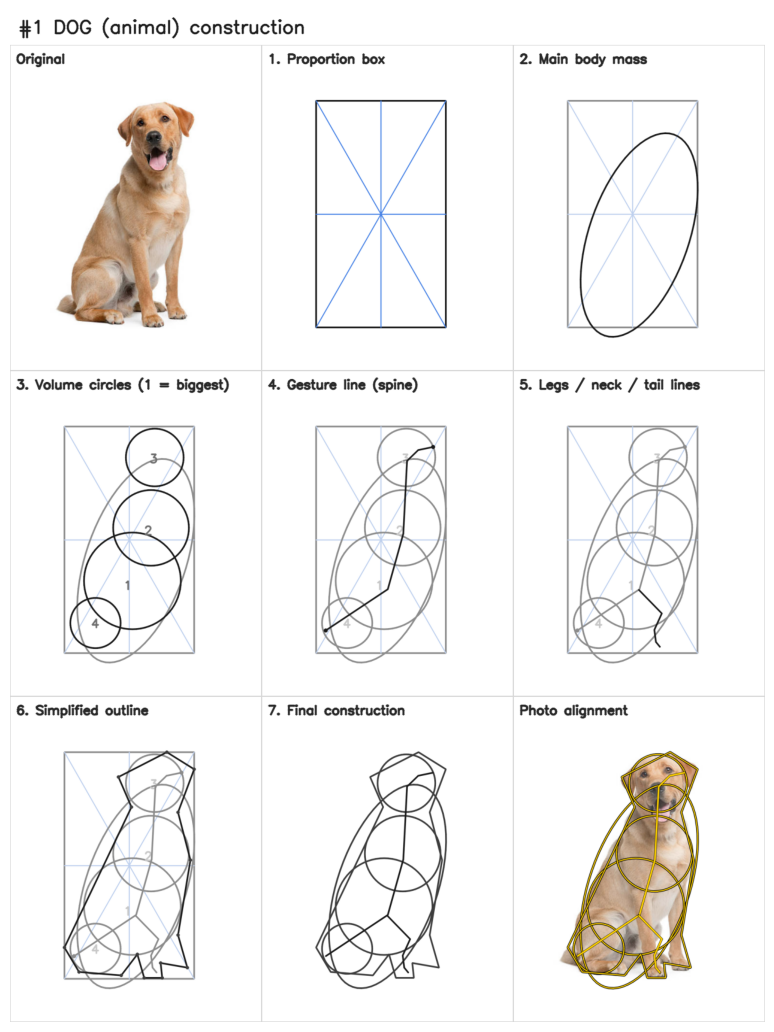

   1. Draw a box with width : height = 0.57 : 1.
   2. Draw one big oval for the body, tilted about -71°.
   3. Add 4 circles (head, chest, hips…) — start with the biggest.
   4. Join them with one smooth gesture line.
   5. Add 1 extra lines for legs / neck / tail / branches.
   6. Connect the outer corners with straight lines — that is your simplified outline.
Segmenting the whole picture (this can take a while on CPU — use SAM_MODEL_TYPE='vit_b' to speed up) …
  sam_official unavailable → RuntimeError: PytorchStreamReader failed reading zip archive: failed finding central directory
  sam_ultralytics unavailable → MemoryError: Insufficient free disk space 0.000 GB < 0.000 GB required, Please free 0.000 GB additional disk space and try 
Segmentation engine: kmeans  →  21 masks → 23 parts
Whole-picture map: 23 parts, 111 shapes, mean coverage 63 %


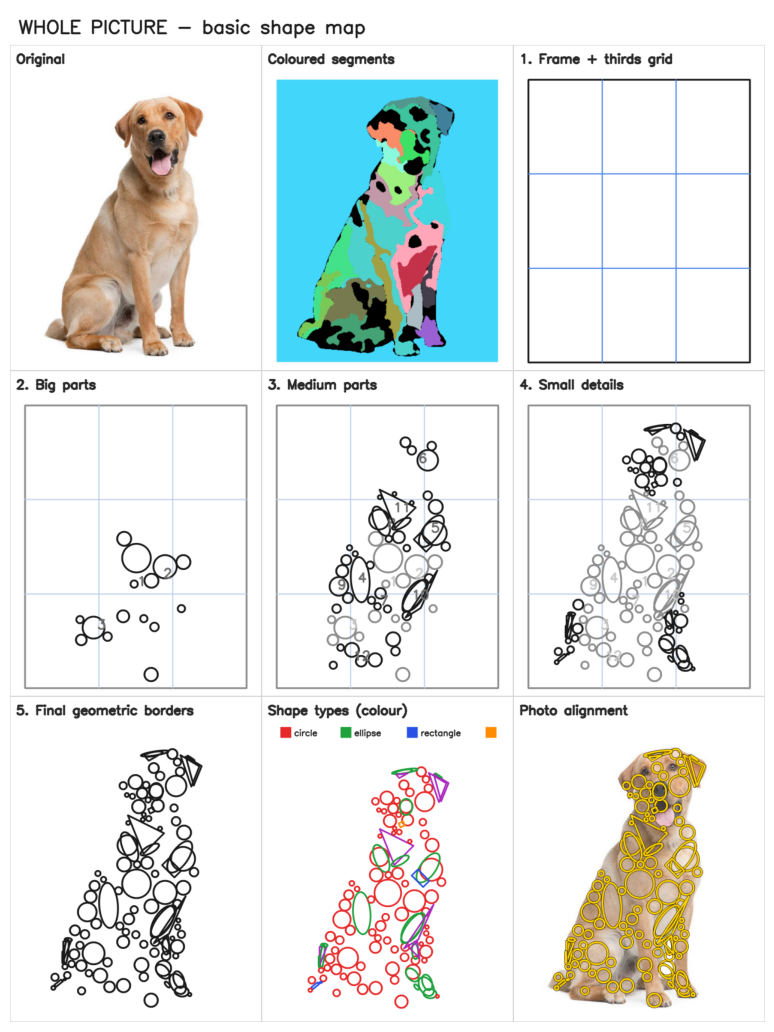

   Part 1: circle + circle + circle + circle + circle  (covers 50 %)
   Part 2: circle + circle + circle + circle + circle  (covers 43 %)
   Part 3: circle + circle + circle + circle + circle  (covers 51 %)
   Part 4: ellipse + circle + circle + circle + circle  (covers 63 %)
   Part 5: circle + circle + ellipse + circle + rectangle  (covers 72 %)
   Part 6: circle + circle + circle + circle + circle  (covers 50 %)
   Part 7: circle + circle + circle + circle + circle  (covers 35 %)
   Part 8: circle + circle + ellipse + circle + circle  (covers 58 %)
   Part 9: circle + circle + circle + circle + circle  (covers 62 %)
   Part 10: ellipse + circle + circle + ellipse + triangle  (covers 79 %)
   Part 11: triangle + ellipse + circle + circle + circle  (covers 80 %)
   Part 12: circle + circle + circle + circle + circle  (covers 53 %)
   … plus 11 smaller parts


In [16]:
def sketch_panels(sk, image, info):
    panels = [("Original", sk.warp(image))] + list(info.get("extra_first", []))
    for i in range(1, sk.step + 1):
        panels.append((f"{i}. {sk.titles[i]}", sk.render(upto=i, highlight=HIGHLIGHT_NEW)))
    panels += list(info.get("extra_panels", []))
    panels.append(("Photo alignment", sk.render(bg=image)))
    return panels


def save_job(name, sk, panels, board):
    d = OUTPUT_DIR / name
    d.mkdir(parents=True, exist_ok=True)
    for i, (title, im) in enumerate(panels):
        safe = "".join(c if c.isalnum() else "_" for c in title)[:30]
        cv2.imwrite(str(d / f"panel_{i:02d}_{safe}.png"), cv2.cvtColor(im, cv2.COLOR_RGB2BGR))
    cv2.imwrite(str(d / "board.png"), cv2.cvtColor(board, cv2.COLOR_RGB2BGR))
    if SAVE_SVG:
        for i in range(1, sk.step + 1):
            sk.to_svg(d / f"step_{i:02d}.svg", upto=i, highlight=HIGHLIGHT_NEW)
    return d


def run_job(name, heading, sk, info, image, results):
    panels = sketch_panels(sk, image, info)
    n = len(panels)
    cols = 3 if n == 9 else (5 if n == 10 else 4)
    board = make_board(panels, cols=cols, heading=heading)
    d = save_job(name, sk, panels, board)
    results.append(dict(name=name, heading=heading, board=board, final=info.get("final", panels[-2][1]), folder=d, info=info))
    plt.figure(figsize=(min(18, 5.2 * cols), 3.1 * math.ceil(n / cols) * 1.35 + 0.6))
    plt.imshow(board); plt.axis("off"); plt.show()
    for line in info.get("recipe", []):
        print("  ", line)


def process_item(it, image, results):
    jobs = []
    if "body" in it.routes:
        sk, info = build_body_sketch(it)
        if sk is None:
            print(f"#{it.idx}: body geometry skipped ({info}).")
        else:
            jobs.append((f"{it.idx:02d}_person_body", f"#{it.idx} PERSON body — {info['view']} view"
                         f"{'' if info['lower'] else ' (upper body only)'} · head from {info['head_source']}", sk, info))
    if "face" in it.routes:
        sk, info = build_face_sketch(image, it.face)
        jobs.append((f"{it.idx:02d}_person_face", f"#{it.idx} FACE — 68 landmarks", sk, info))
    if "creature" in it.routes and it.mask is not None:
        sk, info = build_creature_sketch(it)
        jobs.append((f"{it.idx:02d}_{it.label.replace(' ', '_')}", f"#{it.idx} {it.label.upper()} ({it.category}) construction", sk, info))
    if "shapes" in it.routes and it.mask is not None:
        sk, info = build_shape_sketch(it, image)
        jobs.append((f"{it.idx:02d}_{it.label.replace(' ', '_')}_shapes", f"#{it.idx} {it.label.upper()} — basic shapes", sk, info))
    for name, heading, sk, info in jobs:
        run_job(name, heading, sk, info, image, results)


def run_all(image, items):
    OUTPUT_DIR.mkdir(exist_ok=True)
    results = []
    for it in items:
        try:
            process_item(it, image, results)
        except Exception as e:                           # one bad subject must not stop the others
            print(f"#{it.idx} {it.label}: skipped because of → {type(e).__name__}: {e}")
    if SCENE_SHAPE_MAP or not items:
        sk, info = build_scene_sketch(image)
        run_job("00_scene_shape_map", "WHOLE PICTURE — basic shape map", sk, info, image, results)
    return results


results = run_all(img, items)

## 12. Summary sheet and download

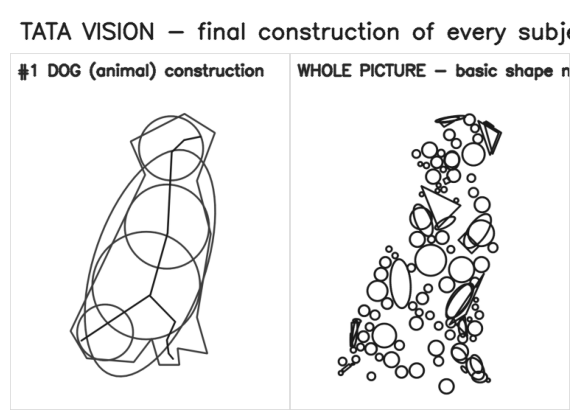

Saved in: /home/ridhurshan/Desktop/new ai/tatavision_output
Zip     : /home/ridhurshan/Desktop/new ai/tatavision_results.zip


In [17]:
if results:
    thumbs = [(r["heading"][:34], r["final"]) for r in results]
    cols = min(4, len(thumbs))
    sheet = make_board(thumbs, cols=cols, tile=(380, 440), heading="TATA VISION — final construction of every subject")
    cv2.imwrite(str(OUTPUT_DIR / "summary_sheet.png"), cv2.cvtColor(sheet, cv2.COLOR_RGB2BGR))
    plt.figure(figsize=(5 * cols, 5.2 * math.ceil(len(thumbs) / cols))); plt.imshow(sheet); plt.axis("off"); plt.show()
    zip_path = shutil.make_archive("tatavision_results", "zip", OUTPUT_DIR)
    print("Saved in:", OUTPUT_DIR.resolve())
    print("Zip     :", zip_path)
    try:
        from google.colab import files
        files.download(zip_path)
    except Exception:
        pass

## 13. How to read the colours, and what to do when something looks wrong
* **Dark strokes** = the step you draw now · **grey** = what you drew before · **light-blue** = construction guides (draw them very lightly, erase later) · yellow on the photo = alignment check.
* **Detector missed or mislabelled something?** Raise `MODEL_SIZE` to `"s"` or `"m"`, lower `CONF`, or switch on `USE_OPEN_VOCAB`. A COCO model can call a goat a "sheep"; the geometry is still valid because it comes from the *mask*, not the name.
* **Face lines do not follow the face?** The 68 dots in the analysis figure must sit on the eyes / nose / mouth / jaw. If not, use a sharper, larger, front-facing photo (faces under ~48 px wide are ignored).
* **Side-view person:** the far arm and leg are dashed. If the near / far choice is wrong, the person is probably facing the other way — the nose keypoint decides it.
* **Only the shoulders show:** the body branch switches to upper-body mode automatically; the face branch carries the detail.
* **Cluttered scene?** Only the `MAX_ITEMS` largest subjects are drawn; the whole-picture shape map still covers everything.
* **Limits that cannot be fixed by settings:** hands and fingers, wings, hidden limbs and exact anatomy are *not* detected — the shapes are drawing guides, not a medical or biological model.